# APM_50441_EP - Machine Learning 2 - Lab 5: Recommender systems and text

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/APM-50441-EP/APM_50441_EP-2026-2027/blob/main/PC5/APM_50441_EP_Lab_5_with_solution.ipynb) or run it on your own computer (see *Working environment* below).

This lab illustrates the fifth lecture (*Recommender Systems, Text and Words*). Its goals are:
- to build the baselines of a recommender system (global mean, user and item biases) and to see the long tail,
- to implement an item-based collaborative filtering,
- to complete the rating matrix with a low-rank model: SVD, Soft-Impute, alternating least squares and a matrix factorization trained by stochastic gradient descent in PyTorch,
- to evaluate the recommendations with ranking metrics, and to see that a good RMSE does not make a good top-$10$ list.

The optional *To go further* part, after the core, can be skipped at first: it covers implicit feedback, evaluation issues (time, sampled metrics, exposure bias, feedback loops), cold start and hybrid models, sequential recommendation, and the text half of the lecture (bag of words, BM25, topic models, word vectors, tokenization, RNN and attention).

We use `Python` with `numpy`, `polars`, `seaborn`, `scikit-learn` and `PyTorch`. All the models are written by hand in `numpy` or `PyTorch`: the specialized libraries (`surprise`, `implicit`, `LightFM`) are not maintained for recent versions of `numpy`.

**Working environment.** Colab is the simplest option: open the notebook of this lab from the course repository (*Open in Colab* link) and run it. To work on your own computer, download the lab folder (the notebook and its files) or clone the course repository, and open the notebook in an IDE that runs Jupyter notebooks (VS Code with the Python and Jupyter extensions, JupyterLab, Spyder, PyCharm). Create a Python environment once with [`uv`](https://docs.astral.sh/uv/): `uv venv`, activate it (`source .venv/bin/activate`, or `.venv\Scripts\activate` on Windows) and `uv pip install jupyter`, or build the whole course environment with `uv sync` in `PC/env`; then select this environment as the kernel of the notebook. The installation cell below installs the packages of the lab into the Python running the notebook (Colab or your environment), and the data are read from the local files when they are present (otherwise they are downloaded).

**Use of AI.** AI assistants are allowed, but you must be able to explain every line you use, and you should answer the *predict before you run* questions before running the code: the suggested code may not be correct!

All the libraries of the core part are installed at once.

In [2]:
# Installs into the Python running this notebook: Colab, or locally an activated virtual environment
import sys
!uv pip install --python "{sys.executable}" "scikit-learn==1.9.1" "polars==1.44.2" "seaborn==0.13.2" "torch"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 4 packages in 92ms


We use the MovieLens 100k data: $100\,000$ ratings ($1$ to $5$ stars) of $1682$ movies by $943$ users, collected by GroupLens in 1997-1998. Its license does not allow redistribution: it is downloaded from the GroupLens website.

In [3]:
import os
import urllib.request
if not os.path.exists("ml-100k.zip"):
  urllib.request.urlretrieve("https://files.grouplens.org/datasets/movielens/ml-100k.zip", "ml-100k.zip")

The data and a random split of the ratings ($80\%$ training, $10\%$ validation, $10\%$ test) are given. The identifiers of the users and the movies start at $1$ in the files: they are shifted to start at $0$, to be used as indices.

In [4]:
import io
import time
import zipfile
import numpy as np
import polars as pl
import seaborn.objects as so
import matplotlib.pyplot as plt
import torch
torch.set_num_threads(2)  # small models: a few threads are faster than many

GENRES = ["unknown", "Action", "Adventure", "Animation", "Children's", "Comedy", "Crime", "Documentary", "Drama", "Fantasy",
          "Film-Noir", "Horror", "Musical", "Mystery", "Romance", "Sci-Fi", "Thriller", "War", "Western"]
with zipfile.ZipFile("ml-100k.zip") as z:
  ratings = pl.read_csv(io.BytesIO(z.read("ml-100k/u.data")), separator="\t", has_header=False,
                        new_columns=["user", "item", "rating", "timestamp"])
  movies = pl.read_csv(io.BytesIO(z.read("ml-100k/u.item")), separator="|", has_header=False, encoding="latin1",
                       new_columns=["item", "title", "release", "video release", "url"] + GENRES)
  users = pl.read_csv(io.BytesIO(z.read("ml-100k/u.user")), separator="|", has_header=False,
                      new_columns=["user", "age", "gender", "occupation", "zip"])
ratings = ratings.with_columns(pl.col("user") - 1, pl.col("item") - 1)
movies = movies.with_columns(pl.col("item") - 1)
users = users.with_columns(pl.col("user") - 1)
n_users, n_items = users.height, movies.height
titles = np.array(movies["title"].to_list())

rng = np.random.default_rng(0)
part = rng.choice(3, size=ratings.height, p=[0.8, 0.1, 0.1])
train, valid, test = [ratings.filter(pl.Series(part == k)) for k in range(3)]
def arrays(df):
  return df["user"].to_numpy(), df["item"].to_numpy(), df["rating"].to_numpy().astype(float)
u_train, i_train, r_train = arrays(train)
u_valid, i_valid, r_valid = arrays(valid)
u_test, i_test, r_test = arrays(test)
def rmse(prediction, r):
  return np.sqrt(np.mean((prediction - r) ** 2))
{'users': n_users, 'movies': n_items, 'training ratings': train.height, 'validation ratings': valid.height, 'test ratings': test.height}

{'users': 943,
 'movies': 1682,
 'training ratings': 80184,
 'validation ratings': 9911,
 'test ratings': 9905}

## 1. The data and the baselines

**Question** What is the proportion of observed entries in the $943 \times 1682$ rating matrix? Plot the distribution of the ratings, and the number of ratings of each movie sorted in decreasing order (log scale). Which share of the ratings concerns the $10\%$ most rated movies? How many movies have fewer than $5$ ratings?

**Answer**

{'density': 0.06304669364224531, 'share of the 10% most rated movies': np.float64(0.42702), 'movies with fewer than 5 ratings': 333}


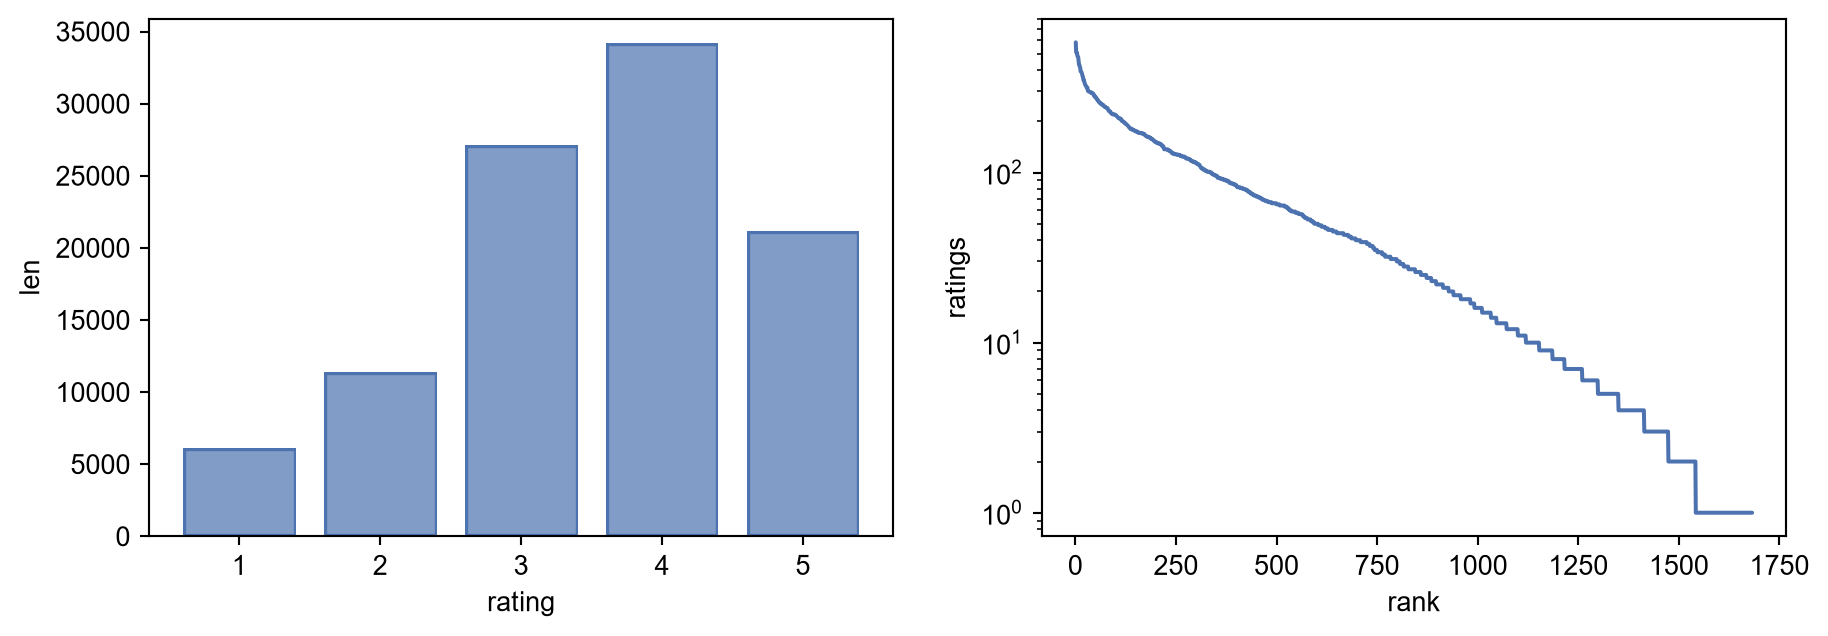

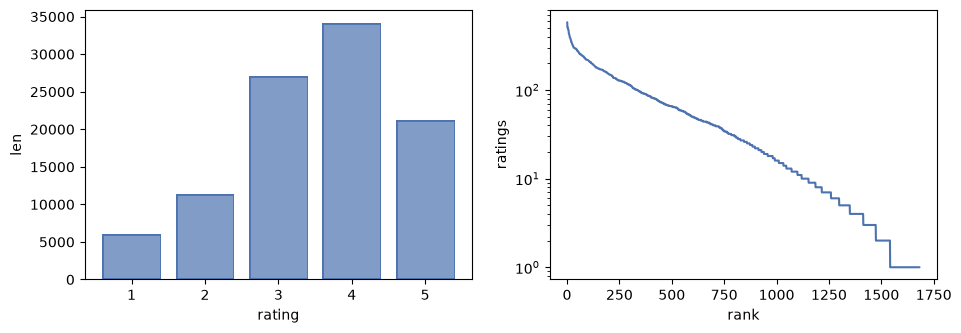

In [5]:
item_counts = np.bincount(ratings["item"].to_numpy(), minlength=n_items)
sorted_counts = np.sort(item_counts)[::-1]
print({'density': ratings.height / (n_users * n_items),
       'share of the 10% most rated movies': sorted_counts[:n_items // 10].sum() / ratings.height,
       'movies with fewer than 5 ratings': int((item_counts < 5).sum())})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
so.Plot(ratings.group_by("rating").len(), x="rating", y="len").add(so.Bar()).on(axes[0]).plot()
so.Plot(pl.DataFrame({"rank": np.arange(1, n_items + 1), "ratings": sorted_counts}), x="rank", y="ratings").add(so.Line()).scale(y="log").on(axes[1]).plot()

**Conclusion** Only $6.3\%$ of the entries of the matrix are observed (and every user rated at least $20$ movies, by construction of the dataset): the matrix is very sparse. The ratings are mostly positive (mode $4$, few $1$ and $2$): people watch, and rate, the movies they expect to like. The number of ratings per movie decreases exponentially with its rank (a straight line in log scale): the $10\%$ most rated movies receive $43\%$ of the ratings, while $333$ movies have fewer than $5$ ratings. This *long tail* is the main difficulty of recommendation: little is known about most items, and naive methods favor the head of the catalog.

---

The simplest predictor is the global mean $\mu$ of the training ratings. The *bias* model (lecture: *Ratings Issues*) adds a user effect and an item effect, $\hat r_{ui} = \mu + b_u + b_i$, fitted by penalized least squares:
$$\min_{b} \sum_{(u,i) \in \Omega} (r_{ui} - \mu - b_u - b_i)^2 + \lambda\Big(\sum_u b_u^2 + \sum_i b_i^2\Big).$$
For fixed item biases, the optimal user bias is $b_u = \frac{\sum_{i \in \Omega_u}(r_{ui} - \mu - b_i)}{|\Omega_u| + \lambda}$, and symmetrically: the problem is solved by alternating these updates (`np.bincount` with weights computes the sums over users or items).

**Question** Compute the validation RMSE of the global mean. Implement the bias model, choose $\lambda \in \{1, 2, 5, 10, 25\}$ on the validation set, and compare the $5$ movies with the highest mean rating with the $5$ movies with the highest bias $b_i$ (with their numbers of ratings). Why is the penalty needed? (Store the global mean in `mu` and the biases obtained with $\lambda = 5$ in `b_user` and `b_item`: they are used below.)

**Answer**

In [6]:
mu = r_train.mean()
def fit_biases(lam, iterations=10):
  b_user, b_item = np.zeros(n_users), np.zeros(n_items)
  n_user, n_item = np.bincount(u_train, minlength=n_users), np.bincount(i_train, minlength=n_items)
  for _ in range(iterations):
    b_user = np.bincount(u_train, r_train - mu - b_item[i_train], n_users) / (n_user + lam)
    b_item = np.bincount(i_train, r_train - mu - b_user[u_train], n_items) / (n_item + lam)
  return b_user, b_item
print({'global mean': rmse(mu, r_valid)} |
      {f'biases, lambda = {lam}': rmse(mu + b[0][u_valid] + b[1][i_valid], r_valid) for lam in [1, 2, 5, 10, 25] for b in [fit_biases(lam)]})
b_user, b_item = fit_biases(5)
movie_stats = (train.group_by("item").agg(pl.col("rating").mean().alias("mean rating"), pl.len().alias("ratings"))
               .join(pl.DataFrame({"item": np.arange(n_items), "title": titles, "bias": b_item}), on="item"))
pl.concat([movie_stats.sort("mean rating", descending=True).head(5), movie_stats.sort("bias", descending=True).head(5)])

{'global mean': np.float64(1.1280424763766483), 'biases, lambda = 1': np.float64(0.9434994916871586), 'biases, lambda = 2': np.float64(0.9427325291022475), 'biases, lambda = 5': np.float64(0.9426145020495051), 'biases, lambda = 10': np.float64(0.9448442548520164), 'biases, lambda = 25': np.float64(0.9547405528057157)}


item,mean rating,ratings,title,bias
i64,f64,u32,str,f64
813,5.0,1,"""Great Day in Harlem, A (1994)""",0.320067
1121,5.0,1,"""They Made Me a Criminal (1939)""",0.20713
1188,5.0,3,"""Prefontaine (1997)""",0.403841
1200,5.0,1,"""Marlene Dietrich: Shadow and L…",0.186304
1292,5.0,2,"""Star Kid (1997)""",0.238452
317,4.481172,239,"""Schindler's List (1993)""",1.038243
482,4.472362,199,"""Casablanca (1942)""",1.02843
168,4.438776,98,"""Wrong Trousers, The (1993)""",1.007254
407,4.43956,91,"""Close Shave, A (1995)""",0.990895


**Conclusion** The global mean has a validation RMSE of $1.13$; adding the user and item biases reduces it to $0.943$ (best $\lambda = 5$): a large part of the predictable variation is explained by users rating systematically high or low and by movies being better or worse than average. Without penalty, the movies with the highest mean rating are obscure movies rated $5$ by one or two users: their mean is pure noise. The penalty shrinks the bias of the movies with few ratings towards $0$ (as a prior, or as Bayesian average ratings), and the highest biases go to movies with hundreds of good ratings: *Schindler's List*, *Casablanca*, *The Shawshank Redemption*...

---

## 2. Item-based collaborative filtering

Collaborative filtering predicts a rating from the ratings of similar items (or users). We work on the *residuals* of the bias model, $\tilde r_{ui} = r_{ui} - \mu - b_u - b_i$, stored in a dense matrix `R` with zeros for the missing entries and a boolean mask `W` of the observed ones. The similarity of two items is the cosine of their residual columns. As two movies seen by few common users can get a large similarity by chance, it is *shrunk* towards $0$: $s_{ij} \times \frac{n_{ij}}{n_{ij} + \beta}$, $n_{ij}$ being the number of users who rated both.

In [7]:
R = np.zeros((n_users, n_items))
W = np.zeros((n_users, n_items), dtype=bool)
R[u_train, i_train] = r_train - mu - b_user[u_train] - b_item[i_train]
W[u_train, i_train] = True
baseline_valid = mu + b_user[u_valid] + b_item[i_valid]
baseline_test = mu + b_user[u_test] + b_item[i_test]

**Question** Compute the cosine similarities between the items, with and without the shrinkage ($\beta = 50$). Display the $5$ movies most similar to *Star Wars (1977)* in both cases. What does the shrinkage change?

**Answer**

In [8]:
norms = np.sqrt((R ** 2).sum(axis=0)) + 1e-9
similarity = (R.T @ R) / np.outer(norms, norms)
np.fill_diagonal(similarity, 0)
common = W.T.astype(float) @ W.astype(float)
shrunk_similarity = similarity * common / (common + 50)
star_wars = int(np.flatnonzero(titles == "Star Wars (1977)")[0])
pl.DataFrame({f'without shrinkage': titles[np.argsort(-similarity[star_wars])[:5]],
              'common users': common[star_wars, np.argsort(-similarity[star_wars])[:5]],
              'with shrinkage': titles[np.argsort(-shrunk_similarity[star_wars])[:5]]})

without shrinkage,common users,with shrinkage
str,f64,str
"""Return of the Jedi (1983)""",310.0,"""Return of the Jedi (1983)"""
"""Empire Strikes Back, The (1980…",214.0,"""Empire Strikes Back, The (1980…"
"""Raiders of the Lost Ark (1981)""",243.0,"""Raiders of the Lost Ark (1981)"""
"""Sting, The (1973)""",136.0,"""Sting, The (1973)"""
"""Indiana Jones and the Last Cru…",182.0,"""Indiana Jones and the Last Cru…"


**Conclusion** The most similar movies to *Star Wars* are its sequels *Return of the Jedi* and *The Empire Strikes Back*, then *Raiders of the Lost Ark*, *The Sting* and *Indiana Jones*: collaborative filtering finds the "same kind of movie" without any information on the content, only from the ratings. For such a popular movie, the shrinkage does not change the list, as all the neighbors share more than $100$ users with it; it matters for the movies with few ratings, whose cosines computed on a handful of common users can be close to $\pm 1$ by chance.

---

**Question** Predict the residual $\tilde r_{ui}$ by the weighted mean $\sum_{j \in N_k(i, u)} s_{ij}\tilde r_{uj} / \sum_{j}|s_{ij}|$ over the $k$ items rated by $u$ that are the most similar to $i$, and add it to the bias model. Compute the validation RMSE for $k \in \{10, 30, 100\}$ with the shrunk similarity.

**Answer**

In [9]:
def item_knn(sim, k, users, items):
  prediction = np.empty(len(users))
  for n, (u, i) in enumerate(zip(users, items)):
    rated = np.flatnonzero(W[u])
    s = sim[i, rated]
    top = np.argsort(-s)[:k]
    prediction[n] = s[top] @ R[u, rated[top]] / (np.abs(s[top]).sum() + 1e-9)
  return prediction
{f'item kNN, k = {k}': rmse(baseline_valid + item_knn(shrunk_similarity, k, u_valid, i_valid), r_valid) for k in [10, 30, 100]}

{'item kNN, k = 10': np.float64(0.9161443030633546),
 'item kNN, k = 30': np.float64(0.9059302832510945),
 'item kNN, k = 100': np.float64(0.9091179632449681)}

**Conclusion** The item-based collaborative filtering improves on the bias model: the validation RMSE goes from $0.943$ to $0.916$ with $k = 10$ neighbors and $0.906$ with $k = 30$, then slightly increases with $k = 100$ ($0.909$), as less similar movies dilute the prediction. As for any $k$-NN, $k$ trades variance (few neighbors) for bias (far neighbors).

---

## 3. Matrix completion

A low-rank model assumes that the matrix of the residuals is close to $UV^\top$, with $U \in \mathbb{R}^{n \times q}$ (the user factors) and $V \in \mathbb{R}^{p \times q}$ (the item factors). The truncated SVD of the zero-filled matrix is the best rank $q$ approximation of `R`, but it treats the missing entries as observed zeros. The weighted problem only fits the observed entries (lecture: *Weighted SVD*); the iterative algorithms below solve it, or its convex relaxation with the nuclear norm (PC5, Exercise 2).

**Question** Compute the SVD of the zero-filled residual matrix (`np.linalg.svd`), and the validation RMSE of the bias model plus its rank $q$ approximation, for $q \in \{1, 2, 5, 10, 20, 50\}$.

**Answer**

In [10]:
U, d, Vt = np.linalg.svd(R, full_matrices=False)
svd_rmse = {q: rmse(baseline_valid + ((U[:, :q] * d[:q]) @ Vt[:q])[u_valid, i_valid], r_valid) for q in [1, 2, 5, 10, 20, 50]}
svd_rmse

{1: np.float64(0.9338048780203969),
 2: np.float64(0.9315492621912524),
 5: np.float64(0.927471699622451),
 10: np.float64(0.9251964017638941),
 20: np.float64(0.9277423483300515),
 50: np.float64(0.9335565480739713)}

**Conclusion** The low-rank approximation of the zero-filled residual matrix only slightly improves on the bias model: $0.925$ at best ($q = 10$), worse than the item kNN. The SVD fits the $94\%$ of missing entries as if they were observed zeros: the factors mostly describe *which* movies were rated, and the predictions are shrunk towards $0$. The weighted problem, which fits only the observed entries, is needed.

---

*Hard-Impute* fills the missing entries with the current estimate $Z$ and projects on the matrices of rank $q$: $Z \leftarrow \text{SVD}_q\big(W \odot R + (1 - W) \odot Z\big)$. *Soft-Impute* replaces the projection by a soft thresholding of the singular values, $d_k \mapsto (d_k - \lambda)_+$, which is the proximal operator of $\lambda\|\cdot\|_*$: it solves $\min_Z \frac{1}{2}\|W \odot (R - Z)\|^2 + \lambda\|Z\|_*$ (PC5). A truncated randomized SVD (`randomized_svd`, $100$ components) keeps the iterations fast.

**Question** Write one function performing Hard-Impute (given a rank) or Soft-Impute (given $\lambda$), with $20$ iterations. Compute the validation RMSE of Hard-Impute for $q \in \{1, 2, 5\}$ and of Soft-Impute along the path $\lambda \in \{40, 20, 15, 10, 7\}$, each solution starting from the previous one (*warm start*); report the rank of each Soft-Impute solution.

**Answer**

In [11]:
from sklearn.utils.extmath import randomized_svd
def impute(rank=None, lam=None, Z=None, iterations=20, components=100):
  Z = np.zeros_like(R) if Z is None else Z
  for _ in range(iterations):
    U, d, Vt = randomized_svd(np.where(W, R, Z), n_components=rank or components, random_state=0)
    if lam is not None:
      d = np.maximum(d - lam, 0)                 # soft thresholding of the singular values
    Z = (U * d) @ Vt
  return Z, int((d > 0).sum())
completion = [{'method': 'Hard-Impute', 'parameter': rank, 'rank': rank,
               'validation RMSE': rmse(baseline_valid + impute(rank=rank)[0][u_valid, i_valid], r_valid)} for rank in [1, 2, 5]]
Z = None
for lam in [40, 20, 15, 10, 7]:
  Z, rank = impute(lam=lam, Z=Z)
  completion.append({'method': 'Soft-Impute', 'parameter': lam, 'rank': rank, 'validation RMSE': rmse(baseline_valid + Z[u_valid, i_valid], r_valid)})
pl.DataFrame(completion)

method,parameter,rank,validation RMSE
str,i64,i64,f64
"""Hard-Impute""",1,1,0.92869
"""Hard-Impute""",2,2,0.932809
"""Hard-Impute""",5,5,0.942511
"""Soft-Impute""",40,0,0.942615
"""Soft-Impute""",20,19,0.921308
"""Soft-Impute""",15,53,0.915299
"""Soft-Impute""",10,96,0.919876
"""Soft-Impute""",7,100,0.932769


**Conclusion** Hard-Impute overfits quickly: its best rank is $q = 1$ ($0.929$) and its error increases with the rank, as each iteration fits the observed entries exactly within the rank constraint. Soft-Impute is much better: along the warm-started path, the validation RMSE decreases from $0.943$ ($\lambda = 40$, all singular values thresholded, rank $0$, that is the bias model) to $0.915$ for $\lambda = 15$ (rank $53$), then increases again for smaller $\lambda$. The nuclear norm penalty shrinks all the singular values instead of keeping a few of them unchanged: a solution of moderately large rank with small singular values generalizes better than a hard low-rank one. The path is cheap thanks to the warm starts (PC5).

---

## 4. Alternating least squares and stochastic gradient descent

The factorization can also be fitted directly on the observed entries, with a ridge penalty (lecture: *Regularized Weighted SVD*):
$$\min_{U, V}\sum_{(u,i) \in \Omega}(\tilde r_{ui} - U_u^\top V_i)^2 + \lambda\big(\|U\|^2 + \|V\|^2\big).$$
For fixed $V$, each row $U_u$ is a ridge regression on the items $\Omega_u$ rated by $u$: $U_u = (V_{\Omega_u}^\top V_{\Omega_u} + \lambda I)^{-1}V_{\Omega_u}^\top \tilde r_{u,\Omega_u}$ (PC5, Exercise 3), and symmetrically for $V$. *Alternating least squares* (ALS) alternates these exact updates.

**Question** Implement ALS ($10$ iterations, random initialization with standard deviation $0.1$), and compute its validation RMSE for $q \in \{5, 10, 20\}$ and $\lambda \in \{10, 20\}$.

**Answer**

In [12]:
rated_by_user = [np.flatnonzero(W[u]) for u in range(n_users)]
raters_of_item = [np.flatnonzero(W[:, i]) for i in range(n_items)]
def als(q, lam, iterations=10, seed=0):
  rng = np.random.default_rng(seed)
  U, V = rng.normal(0, 0.1, (n_users, q)), rng.normal(0, 0.1, (n_items, q))
  for _ in range(iterations):
    for u in range(n_users):
      Vu = V[rated_by_user[u]]
      U[u] = np.linalg.solve(Vu.T @ Vu + lam * np.eye(q), Vu.T @ R[u, rated_by_user[u]])
    for i in range(n_items):
      Ui = U[raters_of_item[i]]
      V[i] = np.linalg.solve(Ui.T @ Ui + lam * np.eye(q), Ui.T @ R[raters_of_item[i], i])
  return U, V
als_rmse = {(q, lam): rmse(baseline_valid + (lambda U, V: (U[u_valid] * V[i_valid]).sum(axis=1))(*als(q, lam)), r_valid)
            for q in [5, 10, 20] for lam in [10, 20]}
als_rmse

{(5, 10): np.float64(0.9217420774629842),
 (5, 20): np.float64(0.9237944233761103),
 (10, 10): np.float64(0.9223561278710206),
 (10, 20): np.float64(0.9218989568934796),
 (20, 10): np.float64(0.9293192521968832),
 (20, 20): np.float64(0.9218280635152015)}

**Conclusion** ALS reaches a validation RMSE of about $0.922$ for all the configurations, except $q = 20$ with the smallest penalty ($0.929$): with more factors, a stronger penalty is needed. It is a little better than the zero-filled SVD, since it only fits the observed ratings, and close to Soft-Impute. Each half-iteration is an exact ridge regression per user or per item, independent of the others: ALS is easy to parallelize, which is why it is used at scale (e.g. in Spark).

---

Stochastic gradient descent (the *Funk SVD* of the Netflix prize) updates the factors one rating, or one mini-batch of ratings, at a time: it scales to huge datasets and to any differentiable model. In `PyTorch`, the factors and the biases are *embeddings* (tables of vectors indexed by the users and the items), and the whole model $\hat r_{ui} = \mu + b_u + b_i + U_u^\top V_i$ is trained jointly.

**Question** Write the biased matrix factorization as a `torch.nn.Module` with `nn.Embedding` layers ($q = 20$, factors initialized with standard deviation $0.01$, biases with $0$), and train it with Adam (learning rate $5\cdot10^{-3}$, mini-batches of $1024$ ratings, $30$ epochs) on the squared loss plus $\lambda$ times the squared norms of the parameters of the batch. Plot the training and validation RMSE along the epochs for $\lambda \in \{0, 0.1\}$. Which epoch would early stopping choose?

**Answer**

shape: (2, 3)
┌────────┬──────────────────────┬────────────┐
│ lambda ┆ best validation RMSE ┆ best epoch │
│ ---    ┆ ---                  ┆ ---        │
│ f64    ┆ f64                  ┆ i64        │
╞════════╪══════════════════════╪════════════╡
│ 0.1    ┆ 0.910209             ┆ 12         │
│ 0.0    ┆ 0.923322             ┆ 3          │
└────────┴──────────────────────┴────────────┘


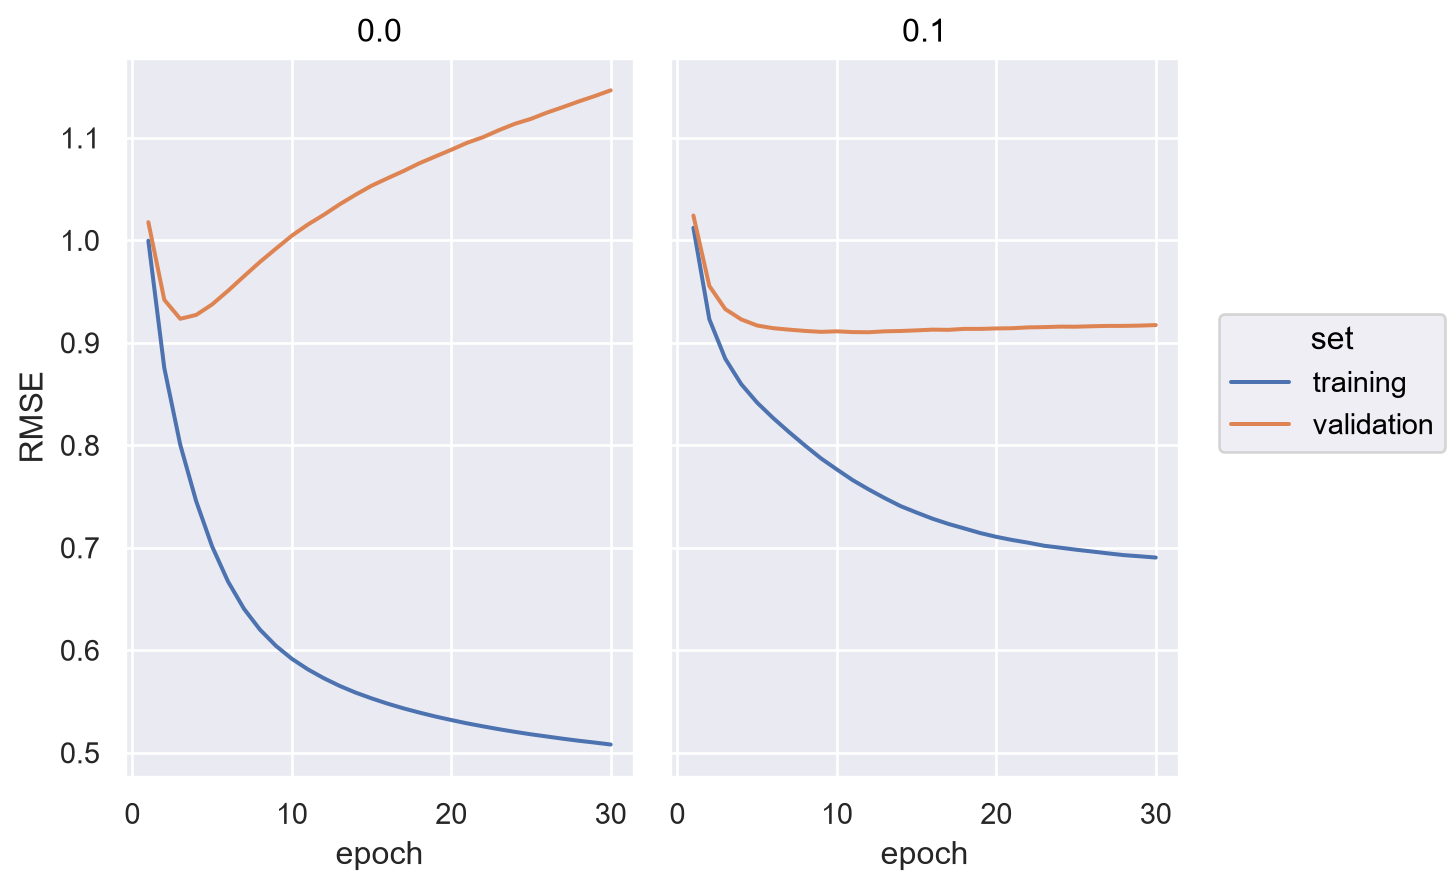

In [13]:
class MatrixFactorization(torch.nn.Module):
  def __init__(self, q):
    super().__init__()
    self.U, self.V = torch.nn.Embedding(n_users, q), torch.nn.Embedding(n_items, q)
    self.b_user, self.b_item = torch.nn.Embedding(n_users, 1), torch.nn.Embedding(n_items, 1)
    torch.nn.init.normal_(self.U.weight, 0, 0.01); torch.nn.init.normal_(self.V.weight, 0, 0.01)
    torch.nn.init.zeros_(self.b_user.weight); torch.nn.init.zeros_(self.b_item.weight)
    self.mu = torch.nn.Parameter(torch.tensor(float(mu)))
  def forward(self, u, i):
    return self.mu + self.b_user(u)[:, 0] + self.b_item(i)[:, 0] + (self.U(u) * self.V(i)).sum(dim=1)
  def penalty(self, u, i):
    return ((self.U(u) ** 2).sum(dim=1) + (self.V(i) ** 2).sum(dim=1) + self.b_user(u)[:, 0] ** 2 + self.b_item(i)[:, 0] ** 2).mean()

def train_mf(q=20, lam=0.1, epochs=30, lr=5e-3, batch=1024, seed=0):
  torch.manual_seed(seed)
  model = MatrixFactorization(q)
  optimizer = torch.optim.Adam(model.parameters(), lr=lr)
  u, i, r = torch.tensor(u_train), torch.tensor(i_train), torch.tensor(r_train, dtype=torch.float32)
  history = []
  for epoch in range(epochs):
    for b in torch.randperm(len(r)).split(batch):
      loss = ((model(u[b], i[b]) - r[b]) ** 2).mean() + lam * model.penalty(u[b], i[b])
      optimizer.zero_grad(); loss.backward(); optimizer.step()
    with torch.no_grad():
      history.append({'epoch': epoch + 1, 'lambda': lam, 'training': rmse(model(u, i).numpy(), r_train),
                      'validation': rmse(model(torch.tensor(u_valid), torch.tensor(i_valid)).numpy(), r_valid)})
  return model, history
histories = []
for lam in [0, 0.1]:
  mf, history = train_mf(lam=lam)
  histories += history
histories = pl.DataFrame(histories)
print(histories.group_by('lambda').agg(pl.col('validation').min().alias('best validation RMSE'),
                                       pl.col('epoch').get(pl.col('validation').arg_min()).alias('best epoch')))
(so.Plot(histories.unpivot(index=['epoch', 'lambda'], variable_name='set', value_name='RMSE'), x='epoch', y='RMSE', color='set')
 .facet(col='lambda').add(so.Line()))

**Conclusion** Without penalty, the factorization overfits after $3$ epochs: the training RMSE keeps decreasing (down to $0.51$) while the validation RMSE increases from $0.923$ to $1.15$. With $\lambda = 0.1$, the validation RMSE decreases until epoch $12$ ($0.910$, the best rating model so far) and stays almost flat afterwards: the penalty makes the training robust to the number of epochs, while early stopping alone would have to stop at epoch $3$. Writing the model in PyTorch costs a few lines and gives SGD, mini-batches and automatic differentiation, which makes it easy to change the model (next blocks).

---

## 5. From ratings to recommendations: ranking metrics

A recommender system shows a short list of items: only the top of the list matters (lecture: *Ranking Metrics*). For each user, we rank *all* the movies he or she has not rated in the training set (ranking against a few sampled movies may change the comparison of the methods, see *Offline Evaluation Pitfalls*), keep the top $K = 10$, and consider as relevant the movies of the test set rated $4$ or $5$. The precision $P@K$ and the recall $R@K$ are the fractions of relevant movies in the list and of the relevant movies in the list; $\text{NDCG}@K$ discounts the hits by $1/\log_2(1 + \text{rank})$ and normalizes by the best possible value; MRR@K averages the reciprocal rank of the first top-K hit, scoring a miss as zero. The averages include users with at least one relevant held-out movie. The *coverage* is the fraction of the catalog that appears in at least one list.

In [14]:
relevant = {}
for u, i, r in zip(u_test, i_test, r_test):
  if r >= 4:
    relevant.setdefault(u, set()).add(i)
def ranking_metrics(scores, K=10):
  """scores: n_users x n_items matrix, the higher the better; the movies of the training set are excluded."""
  discount = 1 / np.log2(np.arange(2, K + 2))
  scores = np.where(W, -np.inf, scores)
  top = np.argpartition(-scores, K - 1, axis=1)[:, :K]
  top = np.take_along_axis(top, np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1), axis=1)
  metrics = []
  for u, rel in relevant.items():
    hits = np.isin(top[u], list(rel))
    metrics.append({f'P@{K}': hits.mean(), f'R@{K}': hits.sum() / len(rel),
                    f'NDCG@{K}': (hits * discount).sum() / discount[:min(len(rel), K)].sum(),
                    f'MRR@{K}': 1 / (np.argmax(hits) + 1) if hits.any() else 0})
  return pl.DataFrame(metrics).mean().with_columns(coverage=pl.lit(len(np.unique(top[list(relevant)])) / n_items))

**Question** *Predict before you run:* which of the methods has the best NDCG@10? Compute the test RMSE and the ranking metrics of: the popularity (number of training ratings of each movie, the same for every user), the bias model, the ALS model ($q = 10$, $\lambda = 20$) and the PyTorch factorization (trained with $\lambda = 0.1$ for the best number of epochs). Display the top $5$ of the first user for each method.

**Answer**

In [15]:
popularity = np.tile(np.bincount(i_train, minlength=n_items).astype(float), (n_users, 1))
biases = mu + b_user[:, None] + b_item[None, :]
U_als, V_als = als(10, 20)
best_epoch = histories.filter(pl.col('lambda') == 0.1).sort('validation')['epoch'][0]
mf, _ = train_mf(lam=0.1, epochs=best_epoch)
with torch.no_grad():
  mf_scores = (mf.mu + mf.b_user.weight + mf.b_item.weight.T + mf.U.weight @ mf.V.weight.T).numpy()
scores = {'popularity': popularity, 'biases': biases, 'ALS': biases + U_als @ V_als.T, 'PyTorch MF': mf_scores}
comparison = pl.concat([ranking_metrics(s).with_columns(method=pl.lit(name),
                         test_RMSE=pl.lit(rmse(s[u_test, i_test], r_test) if name != 'popularity' else None, dtype=pl.Float64)) for name, s in scores.items()])
print(comparison.select('method', 'test_RMSE', 'P@10', 'R@10', 'NDCG@10', 'MRR@10', 'coverage'))
pl.DataFrame({name: titles[np.argsort(-np.where(W[0], -np.inf, s[0]))[:5]] for name, s in scores.items()})

shape: (4, 7)
┌────────────┬───────────┬──────────┬──────────┬──────────┬──────────┬──────────┐
│ method     ┆ test_RMSE ┆ P@10     ┆ R@10     ┆ NDCG@10  ┆ MRR@10   ┆ coverage │
│ ---        ┆ ---       ┆ ---      ┆ ---      ┆ ---      ┆ ---      ┆ ---      │
│ str        ┆ f64       ┆ f64      ┆ f64      ┆ f64      ┆ f64      ┆ f64      │
╞════════════╪═══════════╪══════════╪══════════╪══════════╪══════════╪══════════╡
│ popularity ┆ null      ┆ 0.071564 ┆ 0.130521 ┆ 0.116865 ┆ 0.215452 ┆ 0.029727 │
│ biases     ┆ 0.938191  ┆ 0.039573 ┆ 0.053677 ┆ 0.051842 ┆ 0.107503 ┆ 0.022592 │
│ ALS        ┆ 0.917375  ┆ 0.051303 ┆ 0.065958 ┆ 0.066787 ┆ 0.134081 ┆ 0.057075 │
│ PyTorch MF ┆ 0.908968  ┆ 0.033175 ┆ 0.045553 ┆ 0.046328 ┆ 0.099142 ┆ 0.25327  │
└────────────┴───────────┴──────────┴──────────┴──────────┴──────────┴──────────┘


popularity,biases,ALS,PyTorch MF
str,str,str,str
"""Return of the Jedi (1983)""","""Schindler's List (1993)""","""Casablanca (1942)""","""Two or Three Things I Know Abo…"
"""Fargo (1996)""","""Casablanca (1942)""","""Fargo (1996)""","""Close Shave, A (1995)"""
"""Liar Liar (1997)""","""Wrong Trousers, The (1993)""","""Wrong Trousers, The (1993)""","""They Made Me a Criminal (1939)"""
"""English Patient, The (1996)""","""Close Shave, A (1995)""","""Close Shave, A (1995)""","""Wrong Trousers, The (1993)"""
"""Scream (1996)""","""Shawshank Redemption, The (199…","""Secrets & Lies (1996)""","""Delta of Venus (1994)"""


**Conclusion** The ranking metrics reverse the order given by the RMSE: the PyTorch factorization has the best test RMSE ($0.909$) but the worst NDCG@10 ($0.046$), and the popularity, which predicts no rating at all, has the best NDCG@10 ($0.117$) and MRR@10. The rating models recommend obscure movies that they predict to be very good (*They Made Me a Criminal*, *Delta of Venus*...) but that nobody watches, while the test set only contains movies that the users chose to watch. The bias and ALS models recommend acclaimed classics (*Casablanca*, *Schindler's List*), better but still not what the users watched next. The popularity has a tiny coverage ($3\%$ of the catalog): it shows the same blockbusters to everybody. RMSE is not ranking, and what is evaluated must match what is recommended.

---

The rating models predict well how much a user would like a movie *if he or she watched it*, but the test set only contains the movies the users chose to watch and rate. A top-$N$ recommender must also predict *which* movies a user will watch: this is the *implicit feedback* view, where the data are the pairs $(u, i)$ observed, whatever the rating.

**Question** Build an implicit item-based recommender: from the binary matrix `W` (rated or not), compute the cosine similarities between the items, and score each movie for a user by the sum of its similarities with the movies he or she rated. Compare its ranking metrics with the previous ones.

**Answer**

In [16]:
B = W.astype(float)
item_norms = np.sqrt(B.sum(axis=0)) + 1e-9
implicit_similarity = (B.T @ B) / np.outer(item_norms, item_norms)
np.fill_diagonal(implicit_similarity, 0)
scores['implicit item kNN'] = B @ implicit_similarity
pl.concat([comparison.drop('test_RMSE'), ranking_metrics(scores['implicit item kNN']).with_columns(method=pl.lit('implicit item kNN'))],
          how='diagonal').select('method', 'P@10', 'R@10', 'NDCG@10', 'MRR@10', 'coverage')

method,P@10,R@10,NDCG@10,MRR@10,coverage
str,f64,f64,f64,f64,f64
"""popularity""",0.071564,0.130521,0.116865,0.215452,0.029727
"""biases""",0.039573,0.053677,0.051842,0.107503,0.022592
"""ALS""",0.051303,0.065958,0.066787,0.134081,0.057075
"""PyTorch MF""",0.033175,0.045553,0.046328,0.099142,0.25327
"""implicit item kNN""",0.11481,0.230258,0.203785,0.328223,0.112366


**Conclusion** The implicit item-based recommender, which only uses *which* movies were rated, has the best ranking metrics: NDCG@10 of $0.20$ (almost twice the popularity), recall@10 of $0.23$ and MRR@10 of $0.33$, with a coverage of $11\%$. It models the probability of watching a movie given the movies already watched, which is what a top-$N$ recommendation needs; the ratings themselves are less useful for this task than the fact that a movie was rated.

---

## To go further

The following blocks are optional and independent: each of them only uses the objects defined in the core part (and, for the text blocks, the text data loaded at the beginning of the text part). Their difficulty is marked by stars: ★ direct extension, ★★ new method, ★★★ longer or research-flavored.

| Block | Lecture | Stars |
|---|---|---|
| User-based collaborative filtering | User-based Filtering | ★ |
| Similarities for implicit data | Pearson Correlation and Jaccard Index | ★ |
| Implicit ALS | Weighted Matrix Factorization | ★★ |
| BPR and negative sampling | Negative Sampling | ★★ |
| A temporal split | Offline Evaluation Pitfalls | ★ |
| Sampled ranking metrics | Offline Evaluation Pitfalls | ★★ |
| Blending | Blending as Stacking | ★ |
| Cold start: new movies | Possible Solutions, Demographic Approach | ★★ |
| A factorization machine | Factorization Machines and Deep Variants | ★★ |
| A two-tower model | Two-Tower Models | ★★ |
| Exposure bias and inverse propensity scoring | Exposure Bias and Off-Policy Evaluation | ★★ |
| A feedback loop | Feedback Loops and Popularity Bias | ★★ |
| Fairness and diversity | Fairness and Responsible Recommendation | ★★ |
| An A/B test | Metric vs Goals | ★ |
| Sequential recommendation with a GRU | Sequential Recommendation | ★★★ |
| Bag of words and tf-idf | Text and Bag of Words | ★ |
| A search engine: BM25 | Okapi BM25 | ★ |
| Topics: LSA and a multinomial mixture | Multinomial Mixture Model | ★★ |
| Word vectors from co-occurrences | Truncated SVD Approach | ★★ |
| Word2vec: skip-gram with negative sampling | Supervised Learning Formulation | ★★ |
| A BPE tokenizer | Tokenization | ★★ |
| Recurrent networks | Simple Recurrent Unit, Gated Units | ★★ |
| Attention and a small transformer | Transformers | ★★★ |

### User-based collaborative filtering (★)

The user-based version predicts the residual $\tilde r_{ui}$ from the residuals of the users most similar to $u$ who rated $i$.

**Question** Compute the shrunk cosine similarities between the users ($\beta = 50$), predict with the $k$ most similar users who rated the movie, and compare the validation RMSE with the item-based version for $k \in \{10, 30, 100\}$. Which similarity matrix is larger? Which one would you precompute for a service with millions of users?

**Answer**

In [17]:
user_norms = np.sqrt((R ** 2).sum(axis=1)) + 1e-9
user_similarity = (R @ R.T) / np.outer(user_norms, user_norms)
np.fill_diagonal(user_similarity, 0)
common_items = W.astype(float) @ W.T.astype(float)
user_similarity *= common_items / (common_items + 50)
def user_knn(k, users, items):
  prediction = np.empty(len(users))
  for n, (u, i) in enumerate(zip(users, items)):
    raters = np.flatnonzero(W[:, i])
    s = user_similarity[u, raters]
    top = np.argsort(-s)[:k]
    prediction[n] = s[top] @ R[raters[top], i] / (np.abs(s[top]).sum() + 1e-9)
  return prediction
{f'user kNN, k = {k}': rmse(baseline_valid + user_knn(k, u_valid, i_valid), r_valid) for k in [10, 30, 100]} | {
  'sizes of the similarity matrices (users, items)': (user_similarity.shape, shrunk_similarity.shape)}

{'user kNN, k = 10': np.float64(0.9396015946184004),
 'user kNN, k = 30': np.float64(0.9242527228067202),
 'user kNN, k = 100': np.float64(0.9232291907782146),
 'sizes of the similarity matrices (users, items)': ((943, 943), (1682, 1682))}

**Conclusion** The user-based version is less accurate than the item-based one (best validation RMSE $0.923$ with $k = 100$, against $0.906$), and needs more neighbors. Items are rated by more users than users rate items, and the similarities between items are more stable than the tastes of users. The similarity matrix between users is $943 \times 943$ here, but with millions of users it would be much larger than the one between items, and it changes each time a user rates a movie: services precompute item-item similarities (Amazon's item-to-item collaborative filtering).

---

### Similarities for implicit data (★)

With binary data, the Jaccard index $|A \cap B|/|A \cup B|$ of the sets of users of two items is a natural similarity. As in the tf-idf weighting of the text part, users who rate many movies are less informative: their co-occurrences can be down-weighted, e.g. by $1/\log(2 + n_u)$.

**Question** Compare the ranking metrics of the implicit item-based recommender with the cosine, the Jaccard index, and the cosine computed with the user weights $1/\log(2 + n_u)$.

**Answer**

In [18]:
co_occurrences = B.T @ B
n_raters = B.sum(axis=0)
jaccard = co_occurrences / (n_raters[:, None] + n_raters[None, :] - co_occurrences + 1e-9)
user_weights = 1 / np.log(2 + B.sum(axis=1))
weighted = (B * user_weights[:, None]).T @ B
weighted_cosine = weighted / np.sqrt(np.outer(np.diag(weighted), np.diag(weighted)) + 1e-9)
results = []
for name, similarity_ in {'cosine': implicit_similarity, 'Jaccard': jaccard, 'weighted cosine': weighted_cosine}.items():
  similarity_ = similarity_.copy()
  np.fill_diagonal(similarity_, 0)
  results.append(ranking_metrics(B @ similarity_).with_columns(similarity=pl.lit(name)))
pl.concat(results)

P@10,R@10,NDCG@10,MRR,coverage,similarity
f64,f64,f64,f64,f64,str
0.11481,0.230258,0.203785,0.328223,0.112366,"""cosine"""
0.106635,0.218325,0.191351,0.310204,0.125446,"""Jaccard"""
0.116232,0.23462,0.206088,0.33126,0.114744,"""weighted cosine"""


**Conclusion** The three similarities give close results: the cosine reaches an NDCG@10 of $0.204$, the Jaccard index $0.191$, and the cosine with the users weighted by $1/\log(2 + n_u)$ the best value, $0.206$. Down-weighting the heavy users, as the idf of the text part down-weights the frequent words, gives a small improvement: their co-occurrences are less specific.

---

### Implicit ALS (★★)

Hu, Koren and Volinsky (2008) factorize the *whole* binary matrix $B$, unobserved entries included, with confidence weights $c_{ui} = 1 + \alpha B_{ui}$:
$$\min_{X, Y}\sum_{u, i} c_{ui}(B_{ui} - X_u^\top Y_i)^2 + \lambda(\|X\|^2 + \|Y\|^2).$$
All the $n \times p$ entries are in the loss, but the ALS update stays cheap: $X_u = (Y^\top Y + \alpha Y_{\Omega_u}^\top Y_{\Omega_u} + \lambda I)^{-1}(1 + \alpha)Y_{\Omega_u}^\top\mathbf{1}$, where $Y^\top Y$ is computed once per iteration.

**Question** Implement implicit ALS ($q = 64$, $\lambda = 50$, $10$ iterations) and compute its ranking metrics for $\alpha \in \{1, 10, 40\}$. Compare with the implicit item-based recommender.

**Answer**

In [19]:
def implicit_als(q=64, lam=50, alpha=10, iterations=10, seed=0):
  rng = np.random.default_rng(seed)
  X, Y = rng.normal(0, 0.01, (n_users, q)), rng.normal(0, 0.01, (n_items, q))
  for _ in range(iterations):
    YtY = Y.T @ Y
    for u in range(n_users):
      Yu = Y[rated_by_user[u]]
      X[u] = np.linalg.solve(YtY + alpha * Yu.T @ Yu + lam * np.eye(q), (1 + alpha) * Yu.sum(axis=0))
    XtX = X.T @ X
    for i in range(n_items):
      Xi = X[raters_of_item[i]]
      Y[i] = np.linalg.solve(XtX + alpha * Xi.T @ Xi + lam * np.eye(q), (1 + alpha) * Xi.sum(axis=0))
  return X, Y
results = [ranking_metrics(scores['implicit item kNN']).with_columns(method=pl.lit('implicit item kNN'))]
for alpha in [1, 10, 40]:
  X_ials, Y_ials = implicit_als(alpha=alpha)
  results.append(ranking_metrics(X_ials @ Y_ials.T).with_columns(method=pl.lit(f'implicit ALS, alpha = {alpha}')))
pl.concat(results)

P@10,R@10,NDCG@10,MRR@10,coverage,method
f64,f64,f64,f64,f64,str
0.11481,0.230258,0.203785,0.328223,0.112366,"""implicit item kNN"""
0.114573,0.222537,0.195952,0.32174,0.08264,"""implicit ALS, alpha = 1"""
0.139573,0.277974,0.244563,0.37933,0.280618,"""implicit ALS, alpha = 10"""
0.101777,0.225044,0.17913,0.263635,0.384067,"""implicit ALS, alpha = 40"""


**Conclusion** Implicit ALS with $\alpha = 10$ is the best recommender so far (NDCG@10 $0.245$, MRR@10 $0.38$), with a coverage of $28\%$, much larger than the item kNN. The confidence parameter matters: with $\alpha = 1$, the observed pairs are barely distinguished from the missing ones ($0.196$); with $\alpha = 40$, the model focuses on the observed pairs and recommends less popular movies (coverage $38\%$) at the price of accuracy ($0.179$). The factorization of the whole binary matrix is possible because the cost of each update only depends on the observed entries (the $Y^\top Y$ trick).

---

### BPR and negative sampling (★★)

*Bayesian personalized ranking* (Rendle et al., 2009) learns from pairs: a movie $i$ rated by $u$ should be scored above a movie $j$ drawn uniformly from the training-unrated items of that user (a *negative sample*), $\min -\sum\log\sigma(s_{ui} - s_{uj}) + \lambda\|\theta\|^2$ with $s_{ui} = U_u^\top V_i + b_i$. Its expectation over the negatives is a smooth version of $1 - \text{AUC}$ of each user's ranking.

**Question** Train BPR in PyTorch ($q = 32$, Adam with learning rate $10^{-2}$, mini-batches of $1024$ positive pairs, one uniform training-unrated negative per pair, $20$ epochs). Compare its ranking metrics with implicit ALS, and compute the mean AUC of the users on the test set (relevant test movies against all the movies they did not rate).

**Answer**

In [20]:
def train_bpr(q=32, epochs=20, lr=1e-2, lam=1e-2, seed=0):
  torch.manual_seed(seed)
  U_ = torch.nn.Parameter(0.1 * torch.randn(n_users, q))
  V_ = torch.nn.Parameter(0.1 * torch.randn(n_items, q))
  b_ = torch.nn.Parameter(torch.zeros(n_items))
  optimizer = torch.optim.Adam([U_, V_, b_], lr=lr)
  users_, items_ = torch.tensor(u_train), torch.tensor(i_train)
  seen = torch.from_numpy(W)
  for epoch in range(epochs):
    for batch in torch.randperm(len(users_)).split(1024):
      u, i = users_[batch], items_[batch]
      j = torch.randint(0, n_items, (len(batch),))            # propose uniformly, then reject training positives
      rejected = seen[u, j]
      while rejected.any():
        j[rejected] = torch.randint(n_items, (int(rejected.sum()),))
        rejected = seen[u, j]
      x = (U_[u] * (V_[i] - V_[j])).sum(dim=1) + b_[i] - b_[j]
      loss = -torch.nn.functional.logsigmoid(x).mean() + lam * (U_[u] ** 2 + V_[i] ** 2 + V_[j] ** 2).sum(dim=1).mean()
      optimizer.zero_grad(); loss.backward(); optimizer.step()
  return (U_ @ V_.T + b_).detach().numpy()
scores['BPR'] = train_bpr()
from scipy.stats import rankdata
def mean_auc(s):
  aucs = []
  for u, rel in relevant.items():
    candidates = np.flatnonzero(~W[u])
    positive = np.isin(candidates, list(rel))
    ranks = rankdata(s[u, candidates], method='average') - 1
    n_pos, n_neg = positive.sum(), (~positive).sum()
    aucs.append((ranks[positive].sum() - n_pos * (n_pos - 1) / 2) / (n_pos * n_neg))
  return np.mean(aucs)
pl.concat([ranking_metrics(scores[name]).with_columns(method=pl.lit(name), AUC=pl.lit(mean_auc(scores[name])))
           for name in ['popularity', 'ALS', 'implicit item kNN', 'BPR']])

P@10,R@10,NDCG@10,MRR@10,coverage,method,AUC
f64,f64,f64,f64,f64,str,f64
0.071564,0.130521,0.116865,0.215452,0.029727,"""popularity""",0.876349
0.051303,0.065958,0.066787,0.134081,0.057075,"""ALS""",0.750866
0.11481,0.230258,0.203785,0.328223,0.112366,"""implicit item kNN""",0.910115
0.124052,0.239783,0.206681,0.319295,0.236623,"""BPR""",0.938217


**Conclusion** Sampling a negative from each user’s unrated training items gives BPR an NDCG@10 of $0.207$ and a tie-adjusted AUC of $0.938$. The implicit item kNN scores $0.204$ and $0.910$ on those metrics. BPR leads on AUC among the four methods compared here, while implicit ALS in the preceding block reaches a higher top-ten NDCG. AUC averages across the whole candidate list and gives tied pairs half credit.

---

### A temporal split (★)

A random split of the ratings lets the models use the future to predict the past. The *leave-last-out* split keeps, for each user, his or her last rating for the test, preserving chronology within each user.

**Question** For each user, hold out either the last rated movie (by timestamp) or a random one, and train the popularity and the implicit item-based recommenders on the other ratings. Compare their hit rate $HR@10$ (is the held-out movie in the top $10$?) in both settings.

**Answer**

In [21]:
def hit_rate(held_out, how):
  B_ = np.zeros((n_users, n_items))
  B_[ratings['user'].to_numpy(), ratings['item'].to_numpy()] = 1
  B_[np.arange(n_users), held_out] = 0
  norms_ = np.sqrt(B_.sum(axis=0)) + 1e-9
  sim = (B_.T @ B_) / np.outer(norms_, norms_)
  np.fill_diagonal(sim, 0)
  rows = []
  for name, s in {'popularity': np.tile(B_.sum(axis=0), (n_users, 1)), 'implicit item kNN': B_ @ sim}.items():
    s = np.where(B_ > 0, -np.inf, s)
    top = np.argpartition(-s, 10, axis=1)[:, :10]
    rows.append({'split': how, 'method': name, 'HR@10': np.mean([held_out[u] in top[u] for u in range(n_users)])})
  return rows
last = ratings.sort('timestamp').group_by('user', maintain_order=True).last().sort('user')['item'].to_numpy()
random_one = ratings.sample(fraction=1.0, shuffle=True, seed=0).group_by('user').first().sort('user')['item'].to_numpy()
pl.DataFrame(hit_rate(last, 'leave last out') + hit_rate(random_one, 'leave one random out'))

split,method,HR@10
str,str,f64
"""leave last out""","""popularity""",0.085896
"""leave last out""","""implicit item kNN""",0.109226
"""leave one random out""","""popularity""",0.136797
"""leave one random out""","""implicit item kNN""",0.23754


**Conclusion** With a random held-out movie, the implicit item kNN reaches a hit rate of $0.24$, against $0.11$ when the held-out movie is the last one rated by each user; the popularity also loses ($0.14$ to $0.09$). Predicting the next movie is harder than predicting a random missing one, which can be "interpolated" from the movies watched before and after it. This is a per-user holdout. Other users’ later ratings can influence earlier recommendations. A deployment-time comparison would need a global cutoff or features rebuilt at each prediction time.

---

### Sampled ranking metrics (★★)

To save time, many papers rank each relevant item against $100$ random non-rated items only. Krichene and Rendle (2020) showed that such *sampled* metrics can change the order of the methods.

**Question** For the popularity, the bias model, ALS and the implicit item-based recommender, compute the hit rate $HR@10$ of each relevant test movie ranked among $100$ random movies not rated by the user, and compare the order of the methods with the full-catalog NDCG@10.

**Answer**

In [22]:
rng = np.random.default_rng(1)
def sampled_hit_rate(s, n_negatives=100):
  hits = []
  for u, rel in relevant.items():
    candidates = np.flatnonzero(~W[u] & ~np.isin(np.arange(n_items), list(rel)))
    for i in rel:
      negatives = rng.choice(candidates, n_negatives, replace=False)
      hits.append((s[u, negatives] >= s[u, i]).sum() < 10)
  return np.mean(hits)
pl.DataFrame([{'method': name, 'sampled HR@10': sampled_hit_rate(scores[name]), 'full NDCG@10': ranking_metrics(scores[name])['NDCG@10'][0]}
              for name in ['popularity', 'biases', 'ALS', 'implicit item kNN']])

method,sampled HR@10,full NDCG@10
str,f64,f64
"""popularity""",0.585044,0.116865
"""biases""",0.385997,0.051842
"""ALS""",0.414406,0.066787
"""implicit item kNN""",0.679619,0.203785


**Conclusion** Against $100$ sampled negatives, the hit rates are high ($0.39$ to $0.68$) and much closer to each other than the full-catalog NDCG ($0.05$ to $0.20$): ranking against a few random movies is easy, since most of them are obscure and score low with any method. Here the order of the four methods is the same with both metrics, but the differences are compressed, and Krichene and Rendle showed that the order can change for close methods: the full catalog must be used, as in the core part.

---

### Blending (★)

The winners of the Netflix prize *blended* more than $100$ models: a second-level model (here a linear regression) combines the predictions of the base recommenders, and is trained on held-out ratings (the validation set), as in stacking (Lab 3).

**Question** Fit a linear regression of the validation ratings on the predictions of the bias model, the item kNN ($k = 30$), ALS ($q = 10$, $\lambda = 20$) and the PyTorch factorization, and compare the test RMSE of the blend with the ones of its members.

**Answer**

In [23]:
from sklearn.linear_model import LinearRegression
def members(users, items, baseline):
  with torch.no_grad():
    mf_prediction = mf(torch.tensor(users), torch.tensor(items)).numpy()
  return np.column_stack([baseline, baseline + item_knn(shrunk_similarity, 30, users, items),
                          baseline + (U_als[users] * V_als[items]).sum(axis=1), mf_prediction])
F_valid, F_test = members(u_valid, i_valid, baseline_valid), members(u_test, i_test, baseline_test)
blend = LinearRegression().fit(F_valid, r_valid)
{'weights': blend.coef_.round(2)} | {name: rmse(F_test[:, k], r_test) for k, name in enumerate(['biases', 'item kNN', 'ALS', 'PyTorch MF'])} | {
  'blend': rmse(blend.predict(F_test), r_test)}

{'weights': array([-0.57,  0.59,  0.53,  0.49]),
 'biases': np.float64(0.9381911081027319),
 'item kNN': np.float64(0.9040767139964967),
 'ALS': np.float64(0.9173753735385859),
 'PyTorch MF': np.float64(0.9089684714260463),
 'blend': np.float64(0.8934153939381262)}

**Conclusion** The linear blend reaches a test RMSE of $0.893$, better than its best member (the item kNN, $0.904$). Its weights ($-0.57$ for the biases, about $0.5$ for each of the three other models) show that the blender combines the *residual* corrections of the models, which are partly complementary (neighborhood and factorization). This is the Netflix prize recipe, at the price of maintaining several models in production.

---

### Cold start: new movies (★★)

A new movie has no rating: collaborative filtering cannot use it. Its *content* (genres, release year) can predict its parameters, here its bias $b_i$, from the movies already known (a content-based or *hybrid* approach).

**Question** Draw $10\%$ of the movies as "new", remove all their training ratings, and fit the bias model on the others. Predict the bias of the new movies with a ridge regression on the genres and the release year, trained on the known movies. Compare the RMSE on the test ratings of the new movies of: $\mu + b_u$, $\mu + b_u + \hat b_i(\text{content})$, and $\mu + b_u + b_i$ fitted with their ratings (the oracle).

**Answer**

In [24]:
from sklearn.linear_model import RidgeCV
rng = np.random.default_rng(2)
new = rng.random(n_items) < 0.1
keep = ~new[i_train]
mu_k = r_train[keep].mean()
bu_k, bi_k = np.zeros(n_users), np.zeros(n_items)
for _ in range(10):
  bu_k = np.bincount(u_train[keep], r_train[keep] - mu_k - bi_k[i_train[keep]], n_users) / (np.bincount(u_train[keep], minlength=n_users) + 5)
  bi_k = np.bincount(i_train[keep], r_train[keep] - mu_k - bu_k[u_train[keep]], n_items) / (np.bincount(i_train[keep], minlength=n_items) + 5)
year = movies['release'].str.slice(-4).cast(pl.Float64, strict=False).fill_null(1995).to_numpy()
content = np.column_stack([movies.select(GENRES).to_numpy(), (year - 1990) / 10, ((year - 1990) / 10) ** 2])
known = ~new & (np.bincount(i_train, minlength=n_items) > 0)
ridge = RidgeCV(alphas=np.logspace(-2, 3, 20)).fit(content[known], bi_k[known])
on_new = new[i_test]
u_n, i_n, r_n = u_test[on_new], i_test[on_new], r_test[on_new]
{'new movies': int(new.sum()), 'test ratings of new movies': int(on_new.sum()),
 'user bias only': rmse(mu_k + bu_k[u_n], r_n), 'user bias + content': rmse(mu_k + bu_k[u_n] + ridge.predict(content[i_n]), r_n),
 'oracle (all ratings)': rmse(baseline_test[on_new], r_n)}

{'new movies': 151,
 'test ratings of new movies': 961,
 'user bias only': np.float64(1.0934126290229713),
 'user bias + content': np.float64(1.0405081989789087),
 'oracle (all ratings)': np.float64(0.9608077362530758)}

**Conclusion** For the $151$ new movies, the user biases alone give a test RMSE of $1.093$; adding the item bias predicted from the genres and the release year reduces it to $1.041$, half way to the oracle ($0.961$, with the ratings of these movies). The content explains part of the quality of a movie (e.g. documentaries and dramas are rated higher than horror movies), but not the rest: a hybrid system uses the content at the beginning, and switches to collaborative filtering as soon as ratings arrive.

---

### A factorization machine (★★)

A factorization machine (Rendle, 2010) is a regression on any sparse features $x$ (one-hot user and item, genres, age, occupation...) with all the pairwise interactions, factorized: $\hat y = w_0 + \sum_j w_jx_j + \sum_{j < l}\langle v_j, v_l\rangle x_jx_l$. The interaction term is computed in $O(qd)$ as $\frac{1}{2}\sum_f\big[(\sum_j v_{jf}x_j)^2 - \sum_j v_{jf}^2x_j^2\big]$. With only the user and the item, it is the biased matrix factorization.

**Question** Encode each rating by the indices of its active features (user, item, gender, age group, occupation, genres), train a factorization machine ($q = 20$) in PyTorch with the same training loop as the core part, and compare its validation RMSE with the biased factorization.

**Answer**

In [25]:
age_group = np.digitize(users['age'].to_numpy(), [18, 25, 35, 45, 55])
occupation = users['occupation'].cast(pl.Categorical).to_physical().to_numpy()
offsets = np.cumsum([0, n_users, n_items, 2, 6, occupation.max() + 1])
genre_matrix = movies.select(GENRES).to_numpy()
max_genres = genre_matrix.sum(axis=1).max()
genre_index = np.full((n_items, max_genres), -1)
for i in range(n_items):
  g = np.flatnonzero(genre_matrix[i])
  genre_index[i, :len(g)] = offsets[5] + g
n_features = offsets[5] + len(GENRES)
def encode(u, i):
  base = np.column_stack([u, offsets[1] + i, offsets[2] + (users['gender'].to_numpy()[u] == 'F'),
                          offsets[3] + age_group[u], offsets[4] + occupation[u]])
  index = np.column_stack([base, genre_index[i]])
  return torch.tensor(np.where(index < 0, n_features, index)), torch.tensor(np.where(index < 0, 0.0, 1.0), dtype=torch.float32)

class FactorizationMachine(torch.nn.Module):
  def __init__(self, q):
    super().__init__()
    self.w0 = torch.nn.Parameter(torch.tensor(float(mu)))
    self.w = torch.nn.Embedding(n_features + 1, 1, padding_idx=n_features)
    self.v = torch.nn.Embedding(n_features + 1, q, padding_idx=n_features)
    torch.nn.init.zeros_(self.w.weight); torch.nn.init.normal_(self.v.weight, 0, 0.01)
  def forward(self, index, value):
    v, x = self.v(index), value[:, :, None]
    interactions = 0.5 * (((v * x).sum(dim=1)) ** 2 - ((v * x) ** 2).sum(dim=1)).sum(dim=1)
    return self.w0 + (self.w(index)[:, :, 0] * value).sum(dim=1) + interactions
  def penalty(self, index, value):
    return ((self.v(index) ** 2).sum(dim=2) + self.w(index)[:, :, 0] ** 2).sum(dim=1).mean()

torch.manual_seed(0)
fm = FactorizationMachine(20)
optimizer = torch.optim.Adam(fm.parameters(), lr=5e-3)
index_train, value_train = encode(u_train, i_train)
index_valid, value_valid = encode(u_valid, i_valid)
r_t = torch.tensor(r_train, dtype=torch.float32)
fm_history = []
for epoch in range(15):
  for b in torch.randperm(len(r_t)).split(1024):
    loss = ((fm(index_train[b], value_train[b]) - r_t[b]) ** 2).mean() + 0.1 * fm.penalty(index_train[b], value_train[b])
    optimizer.zero_grad(); loss.backward(); optimizer.step()
  with torch.no_grad():
    fm_history.append(rmse(fm(index_valid, value_valid).numpy(), r_valid))
{'factorization machine, best validation RMSE': min(fm_history), 'at epoch': int(np.argmin(fm_history)) + 1,
 'biased MF, best validation RMSE': histories.filter(pl.col('lambda') == 0.1)['validation'].min()}

{'factorization machine, best validation RMSE': np.float64(0.9029402109895314),
 'at epoch': 15,
 'biased MF, best validation RMSE': 0.9102089116846803}

**Conclusion** The factorization machine reaches a validation RMSE of $0.903$, better than the biased matrix factorization ($0.910$): the side information (genres, age, gender, occupation) and its interactions with the users and the items help, in particular for the users and the movies with few ratings. The factorized interactions keep the number of parameters linear in the number of features, and the model is a few lines of PyTorch.

---

### A two-tower model (★★)

Industrial recommenders first *retrieve* a few hundred candidates among millions of items with a *two-tower* model: a user tower and an item tower map their features to vectors whose dot product is the score, so that the item vectors can be indexed for a fast nearest neighbor search. It is trained on the observed pairs with an *in-batch softmax*: in a batch of pairs $(u_k, i_k)$, each user must recognize its own item among the items of the other pairs. As popular items appear more often in the batches, they are penalized more often as negatives: the *logQ correction* subtracts from each logit the log of the frequency of the item (Yi et al., 2019).

**Question** Train a two-tower model: the user tower embeds the user, gender, age group and occupation, the item tower the movie and its genres, each followed by a linear layer to dimension $32$; use the in-batch softmax loss with a temperature $0.1$ on mini-batches of $512$ training pairs, $10$ epochs, without and with the logQ correction. Compute their ranking metrics.

**Answer**

In [26]:
user_features = torch.tensor(np.column_stack([np.arange(n_users), users['gender'].to_numpy() == 'F', age_group, occupation]))
item_genres = torch.tensor(genre_matrix, dtype=torch.float32)
class TwoTowers(torch.nn.Module):
  def __init__(self, d=32):
    super().__init__()
    self.user = torch.nn.ModuleList([torch.nn.Embedding(n, d) for n in [n_users, 2, 6, occupation.max() + 1]])
    self.item = torch.nn.Embedding(n_items, d)
    self.genres = torch.nn.Linear(len(GENRES), d)
    self.user_out, self.item_out = torch.nn.Linear(d, d), torch.nn.Linear(d, d)
  def users(self, u):
    return torch.nn.functional.normalize(self.user_out(sum(e(user_features[u, k]) for k, e in enumerate(self.user))), dim=1)
  def items(self, i):
    return torch.nn.functional.normalize(self.item_out(self.item(i) + self.genres(item_genres[i])), dim=1)
users_t, items_t = torch.tensor(u_train), torch.tensor(i_train)
item_frequency = np.bincount(i_train, minlength=n_items) + 1
log_q = torch.tensor(np.log(item_frequency / item_frequency.sum()), dtype=torch.float32)
for name, correction in [('two towers', False), ('two towers, logQ correction', True)]:
  torch.manual_seed(0)
  towers = TwoTowers()
  optimizer = torch.optim.Adam(towers.parameters(), lr=1e-2)
  for epoch in range(10):
    for b in torch.randperm(len(users_t)).split(512):
      logits = towers.users(users_t[b]) @ towers.items(items_t[b]).T / 0.1
      if correction:
        logits = logits - log_q[items_t[b]][None, :]
      loss = torch.nn.functional.cross_entropy(logits, torch.arange(len(b)))
      optimizer.zero_grad(); loss.backward(); optimizer.step()
  with torch.no_grad():
    scores[name] = (towers.users(torch.arange(n_users)) @ towers.items(torch.arange(n_items)).T).numpy()
pl.concat([ranking_metrics(scores[name]).with_columns(method=pl.lit(name))
           for name in ['popularity', 'implicit item kNN', 'two towers', 'two towers, logQ correction']])

P@10,R@10,NDCG@10,MRR,coverage,method
f64,f64,f64,f64,f64,str
0.071564,0.130521,0.116865,0.215452,0.029727,"""popularity"""
0.11481,0.230258,0.203785,0.328223,0.112366,"""implicit item kNN"""
0.017299,0.034945,0.025514,0.043186,0.920333,"""two towers"""
0.120379,0.22244,0.197469,0.317558,0.385256,"""two towers, logQ correction"""


**Conclusion** Without correction, the two-tower model is very poor (NDCG@10 $0.026$) and recommends almost the whole catalog (coverage $92\%$): the popular movies, which appear in most batches, are constantly pushed down as negatives, and the model learns to recommend rare movies. With the logQ correction, it reaches an NDCG@10 of $0.197$, close to the implicit item kNN ($0.204$), with a much larger coverage ($39\%$ against $11\%$). The two-tower structure is what makes retrieval scalable (item vectors indexed for approximate nearest neighbor search), but its training must take the sampling of the negatives into account.

---

### Exposure bias and inverse propensity scoring (★★)

Logged data only concern the items shown by the deployed recommender (the *logging policy* $\pi_0$). The value of a new policy $\pi$ cannot be estimated by the mean reward of the logs, but it can by *inverse propensity scoring*: $\hat V_{\text{IPS}}(\pi) = \frac{1}{N}\sum_k\frac{\pi(a_k|x_k)}{\pi_0(a_k|x_k)}r_k$, unbiased if $\pi_0 > 0$ wherever $\pi > 0$ (lecture, after Schnabel et al.). We simulate a world in which the probability that user $u$ likes movie $i$ is $p_{ui} = \sigma(2(\hat r_{ui} - 3.5))$, $\hat r$ being the ALS predictions.

**Question** Simulate $20$ logs of $N = 20\,000$ recommendations: a random user, a movie drawn from the logging policy $\pi_0(i)=0.95\,q(i)+0.05/n_{\rm items}$ with $q(i)\propto\sqrt{\text{training count of }i}$, and a reward drawn with probability $p_{ui}$. For the new policy $\pi(i|u) \propto \exp(2\hat r_{ui})$, compare its true value with the naive estimate (mean reward of the logs), the IPS and the self-normalized IPS estimates (mean and standard deviation over the $20$ logs).

**Answer**

In [27]:
rating_hat = biases + U_als @ V_als.T
p_like = 1 / (1 + np.exp(-2 * (rating_hat - 3.5)))
pi_0 = np.bincount(i_train, minlength=n_items) ** 0.5
pi_0 = 0.95 * pi_0 / pi_0.sum() + 0.05 / n_items
pi_new = np.exp(2 * (rating_hat - rating_hat.max(axis=1, keepdims=True)))
pi_new /= pi_new.sum(axis=1, keepdims=True)
true_value = (pi_new * p_like).sum(axis=1).mean()
rng = np.random.default_rng(3)
estimates = []
for log in range(20):
  u = rng.integers(n_users, size=20_000)
  a = rng.choice(n_items, size=20_000, p=pi_0)
  r = rng.random(20_000) < p_like[u, a]
  w = pi_new[u, a] / pi_0[a]
  estimates.append({'naive': r.mean(), 'IPS': (w * r).mean(), 'self-normalized IPS': (w * r).sum() / w.sum()})
estimates = pl.DataFrame(estimates)
{'true value of the new policy': true_value, 'value of the logging policy': (pi_0 * p_like).sum(axis=1).mean()} | {
  name: f"{estimates[name].mean():.4f} +/- {estimates[name].std():.4f}" for name in estimates.columns}

{'true value of the new policy': np.float64(0.5934690104764474),
 'value of the logging policy': np.float64(0.4948186141173037),
 'naive': '0.4948 +/- 0.0036',
 'IPS': '0.5945 +/- 0.0066',
 'self-normalized IPS': '0.5936 +/- 0.0047'}

**Conclusion** With $5\%$ uniform exploration, every movie has positive logging probability. The naive reward estimate is $0.4948$, matching the logging policy value. Across 20 logs, IPS gives $0.5945$ (SD $0.0066$) and self-normalized IPS gives $0.5936$ (SD $0.0047$), against a true target value of $0.5935$. Self-normalization reduced the observed spread in this experiment.

---

### A feedback loop (★★)

A recommender is trained on what it has shown: popular items get more exposure, hence more interactions, hence more exposure (lecture, after Chaney et al.). Exploration breaks the loop.

**Question** In the simulated world of the previous block ($p_{ui}$ recomputed as there), run $30$ rounds in which every user is shown $10$ movies and clicks each of them with probability $p_{ui}$. Compare two systems: a *greedy* one, which shows to everybody the $10$ movies with the most clicks so far (starting with random movies), and an *exploring* one, which shows the $8$ movies with the best estimated click rate $(\text{clicks} + 1)/(\text{shows} + 2)$ and $2$ random movies. Plot the click rate along the rounds and report the number of distinct movies shown. What does the greedy system learn about the catalog?

**Answer**

{'greedy': {'click rate, last 10 rounds': np.float64(0.4735737009544009),
  'distinct movies shown': 10},
 'exploring': {'click rate, last 10 rounds': np.float64(0.7554718981972429),
  'distinct movies shown': 1682},
 'best possible click rate (top 10 for each user)': np.float64(0.8517005290738208)}

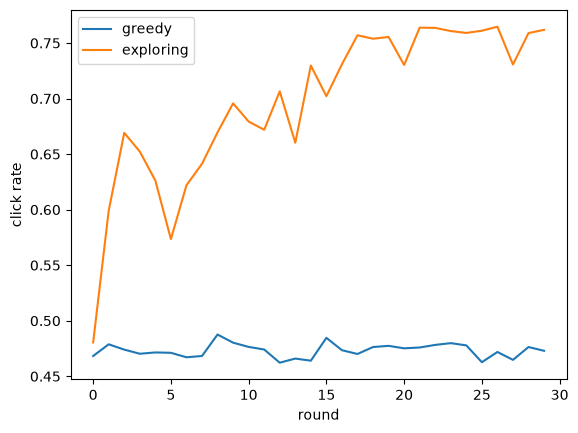

In [28]:
rating_hat = biases + U_als @ V_als.T
p_like = 1 / (1 + np.exp(-2 * (rating_hat - 3.5)))
def feedback_loop(explore, rounds=30, seed=4):
  rng = np.random.default_rng(seed)
  clicks, shows, shown, click_rates = np.zeros(n_items), np.zeros(n_items), np.zeros(n_items, dtype=bool), []
  for r in range(rounds):
    if explore:
      top = np.argsort(-(clicks + 1) / (shows + 2) - 1e-9 * rng.random(n_items))[:8]
      slates = np.column_stack([np.tile(top, (n_users, 1)), rng.integers(n_items, size=(n_users, 2))])
    else:
      top = np.argsort(-clicks - 1e-9 * rng.random(n_items))[:10]       # random movies in the first round
      slates = np.tile(top, (n_users, 1))
    clicked = rng.random(slates.shape) < np.take_along_axis(p_like, slates, axis=1)
    np.add.at(shows, slates.ravel(), 1)
    np.add.at(clicks, slates.ravel(), clicked.ravel())
    shown[slates.ravel()] = True
    click_rates.append(clicked.mean())
  return click_rates, int(shown.sum())
loops = {name: feedback_loop(explore) for name, explore in [('greedy', False), ('exploring', True)]}
for name, (rates, _) in loops.items():
  plt.plot(rates, label=name)
plt.xlabel('round'); plt.ylabel('click rate'); plt.legend()
{name: {'click rate, last 10 rounds': np.mean(rates[-10:]), 'distinct movies shown': distinct} for name, (rates, distinct) in loops.items()} | {
  'best possible click rate (top 10 for each user)': np.sort(p_like, axis=1)[:, -10:].mean()}

**Conclusion** The greedy system shows the same $10$ movies to everybody from the first round on: the movies chosen at random in the first round get all the clicks, so they stay on top forever, and the click rate stays at $0.47$. It has learned nothing about the other $1672$ movies. The exploring system shows the whole catalog through its random slots, finds the movies that are really liked, and reaches a click rate of $0.76$, close to the best possible personalized rate ($0.85$) although it shows the same $8$ movies to everybody. Without exploration, a recommender only confirms its own past choices; the exploration/exploitation trade-off is the bandit view of recommendation (Lecture 6).

---

### Fairness and diversity (★★)

Fairness has two sides: the *users* (similar quality for all groups) and the *providers* (a fair exposure of the items). A simple re-ranking divides the scores by a power of the popularity to expose the long tail.

**Question** For the implicit item-based recommender, compute the NDCG@10 by gender and by age group of the users. Then re-rank with the scores divided by $(\text{popularity})^\gamma$ for $\gamma \in \{0, 0.1, 0.2, 0.3\}$ and report the NDCG@10, the coverage and the share of the recommendations going to the $10\%$ most rated movies.

**Answer**

In [29]:
def per_user_ndcg(s, K=10):
  discount = 1 / np.log2(np.arange(2, K + 2))
  s = np.where(W, -np.inf, s)
  top = np.argsort(-s, axis=1)[:, :K]
  return {u: (np.isin(top[u], list(rel)) * discount).sum() / discount[:min(len(rel), K)].sum() for u, rel in relevant.items()}, top
ndcg_users, _ = per_user_ndcg(scores['implicit item kNN'])
user_quality = users.with_columns(age_group=pl.Series(age_group)).join(
  pl.DataFrame({'user': list(ndcg_users), 'NDCG@10': list(ndcg_users.values())}), on='user')
print(user_quality.group_by('gender').agg(pl.col('NDCG@10').mean(), pl.len()).sort('gender'))
print(user_quality.group_by('age_group').agg(pl.col('NDCG@10').mean(), pl.len()).sort('age_group'))
item_popularity = np.bincount(i_train, minlength=n_items) + 1
head = np.argsort(-item_popularity)[:n_items // 10]
rows = []
for gamma in [0, 0.1, 0.2, 0.3]:
  ndcg_, top = per_user_ndcg(scores['implicit item kNN'] / item_popularity ** gamma)
  rows.append({'gamma': gamma, 'NDCG@10': np.mean(list(ndcg_.values())), 'coverage': len(np.unique(top)) / n_items,
               'share of the 10% most rated movies': np.isin(top, head).mean()})
pl.DataFrame(rows)

shape: (2, 3)
┌────────┬──────────┬─────┐
│ gender ┆ NDCG@10  ┆ len │
│ ---    ┆ ---      ┆ --- │
│ str    ┆ f64      ┆ u32 │
╞════════╪══════════╪═════╡
│ F      ┆ 0.183138 ┆ 240 │
│ M      ┆ 0.211989 ┆ 604 │
└────────┴──────────┴─────┘
shape: (6, 3)
┌───────────┬──────────┬─────┐
│ age_group ┆ NDCG@10  ┆ len │
│ ---       ┆ ---      ┆ --- │
│ i64       ┆ f64      ┆ u32 │
╞═══════════╪══════════╪═════╡
│ 0         ┆ 0.343403 ┆ 29  │
│ 1         ┆ 0.182928 ┆ 180 │
│ 2         ┆ 0.195841 ┆ 280 │
│ 3         ┆ 0.192734 ┆ 176 │
│ 4         ┆ 0.231093 ┆ 124 │
│ 5         ┆ 0.212658 ┆ 55  │
└───────────┴──────────┴─────┘


gamma,NDCG@10,coverage,share of the 10% most rated movies
f64,f64,f64,f64
0.0,0.203785,0.115339,0.968929
0.1,0.194137,0.168252,0.909544
0.2,0.146218,0.303805,0.701697
0.3,0.047035,0.410226,0.218452


**Conclusion** The quality of the recommendations differs between groups: the NDCG@10 is $0.18$ for women and $0.21$ for men, and varies with the age group from $0.18$ to $0.34$ (the youngest group has only $29$ users: its value is very noisy). On the provider side, $97\%$ of the recommended slots go to the $10\%$ most rated movies. Dividing the scores by the popularity to a small power changes this: with $\gamma = 0.1$, the NDCG@10 only decreases from $0.204$ to $0.194$ while the coverage increases from $12\%$ to $17\%$; with $\gamma = 0.2$, the coverage reaches $30\%$ for an NDCG of $0.146$; with $\gamma = 0.3$, the accuracy collapses ($0.047$). There is a trade-off between accuracy and exposure, and the right point is a choice of the platform, not of the algorithm.

---

### An A/B test (★)

Offline metrics are only proxies: a new recommender is finally evaluated online, by an A/B test on the metric that matters (clicks, purchases, retention). With a click rate $p$ and $n$ users per group, the difference of the observed rates has a standard deviation $\approx\sqrt{2p(1-p)/n}$.

**Question** How many users per group are needed to detect an increase of the click rate from $5\%$ to $5.25\%$ (a $5\%$ relative lift) with a two-sided test at level $5\%$ and a power of $80\%$? Check the power by simulating $2000$ A/B tests with this size. With $100\,000$ visitors per day, how long does the test last?

**Answer**

In [30]:
from scipy import stats
p0, p1, alpha, power = 0.05, 0.0525, 0.05, 0.8
z = stats.norm.ppf(1 - alpha / 2) + stats.norm.ppf(power)
n = int(np.ceil(z ** 2 * (p0 * (1 - p0) + p1 * (1 - p1)) / (p1 - p0) ** 2))
rng = np.random.default_rng(5)
a, b = rng.binomial(n, p0, 2000) / n, rng.binomial(n, p1, 2000) / n
pooled = (a + b) / 2
rejected = np.abs(b - a) / np.sqrt(2 * pooled * (1 - pooled) / n) > stats.norm.ppf(1 - alpha / 2)
{'users per group': n, 'simulated power': rejected.mean(), 'days with 100 000 visitors per day': 2 * n / 100_000}

{'users per group': 122121,
 'simulated power': np.float64(0.7935),
 'days with 100 000 visitors per day': 2.44242}

**Conclusion** Detecting a $5\%$ relative lift of a $5\%$ click rate requires about $122\,000$ users per group ($244\,000$ in total), and the simulation confirms a power of $79\%$. With $100\,000$ visitors per day, the test lasts about $2.5$ days (in practice one or two full weeks, to cover the weekly cycles). Small effects on rare events need very large samples: this is why offline evaluation is used to select the few candidates worth an online test.

---

### Sequential recommendation with a GRU (★★★)

The order of the interactions carries information: what a user watches next depends on what he or she just watched. A sequential recommender (GRU4Rec, SASRec) reads the sequence of the items of a user and predicts the next one, as a language model predicts the next word.

**Question** Sort the ratings of each user by time, hold out the last movie, and train a GRU (embeddings and hidden state of dimension $64$, last $50$ movies of each sequence) to predict each next movie from the previous ones with the cross-entropy over all the movies ($20$ epochs, Adam). Compare its $HR@10$ on the held-out movies with the popularity and with the implicit item-based scores of the previous movie only ("users who watched this also watched").

**Answer**

In [31]:
sequences = [s.to_numpy() for s in ratings.sort('timestamp').group_by('user', maintain_order=True).agg('item').sort('user')['item']]
inputs = [s[:-1][-51:] for s in sequences]                   # the history, the last movie being held out
held_out = np.array([s[-1] for s in sequences])
L = max(len(s) for s in inputs)
padded = torch.full((n_users, L), n_items)                    # index n_items = padding (on the left)
for u, s in enumerate(inputs):
  padded[u, L - len(s):] = torch.tensor(s)
class GRURecommender(torch.nn.Module):
  def __init__(self, d=64):
    super().__init__()
    self.embedding = torch.nn.Embedding(n_items + 1, d, padding_idx=n_items)
    self.gru = torch.nn.GRU(d, d, batch_first=True)
    self.out = torch.nn.Linear(d, n_items)
  def forward(self, x):
    return self.out(self.gru(self.embedding(x))[0])
torch.manual_seed(0)
gru = GRURecommender()
optimizer = torch.optim.Adam(gru.parameters(), lr=5e-3)
x, y = padded[:, :-1], padded[:, 1:]
for epoch in range(20):
  for b in torch.randperm(n_users).split(64):
    logits = gru(x[b])
    loss = torch.nn.functional.cross_entropy(logits.reshape(-1, n_items), y[b].reshape(-1), ignore_index=n_items)
    optimizer.zero_grad(); loss.backward(); optimizer.step()
seen = np.zeros((n_users, n_items), dtype=bool)
for u, s in enumerate(sequences):
  seen[u, s[:-1]] = True
with torch.no_grad():
  next_scores = gru(padded)[:, -1].numpy()
B_seq = seen.astype(float)
sim_seq = (B_seq.T @ B_seq) / np.outer(np.sqrt(B_seq.sum(0)) + 1e-9, np.sqrt(B_seq.sum(0)) + 1e-9)
np.fill_diagonal(sim_seq, 0)
def hr10(s):
  s = np.where(seen, -np.inf, s)
  return np.mean([held_out[u] in np.argpartition(-s[u], 10)[:10] for u in range(n_users)])
{'popularity': hr10(np.tile(B_seq.sum(0), (n_users, 1))), 'previous movie (item kNN)': hr10(sim_seq[[s[-2] for s in sequences]]),
 'all the history (item kNN)': hr10(B_seq @ sim_seq), 'GRU': hr10(next_scores)}

{'popularity': np.float64(0.08589607635206786),
 'previous movie (item kNN)': np.float64(0.15588547189819724),
 'all the history (item kNN)': np.float64(0.10922587486744433),
 'GRU': np.float64(0.13891834570519618)}

**Conclusion** The GRU predicts the next movie with a hit rate of $0.139$, better than the popularity ($0.086$) and than the item kNN using the whole history ($0.109$), but below the item kNN using only the *previous* movie ($0.156$). The order of the movies matters (the last movie is the most informative), and a simple model exploiting it is a strong baseline; with $943$ short sequences, the GRU does not have enough data to beat it. Sequential recommenders (GRU4Rec, SASRec, and the generative recommenders of the lecture) shine with millions of long sequences.

---

### Text data (support for the text blocks)

The text blocks use $6$ newsgroups of the *20 newsgroups* corpus (messages posted in 1993, without their headers, signatures and quotes), downloaded by `scikit-learn`. The tokenizer keeps the lowercase alphabetic words of at least $2$ letters.

In [32]:
import re
from sklearn.datasets import fetch_20newsgroups
CATEGORIES = ['comp.graphics', 'rec.autos', 'rec.sport.hockey', 'sci.med', 'sci.space', 'talk.politics.guns']
news = fetch_20newsgroups(subset='all', categories=CATEGORIES, remove=('headers', 'footers', 'quotes'), random_state=0)
def tokenize(text):
  return re.findall(r"[a-z]{2,}", text.lower())
documents, newsgroup = news.data, news.target
tokens = [tokenize(d) for d in documents]
{'documents': len(documents), 'tokens': sum(len(t) for t in tokens)}

{'documents': 5849, 'tokens': 961819}

### Bag of words and tf-idf (★)

A document is represented by the counts $h_w(d)$ of the words of a vocabulary (the order is lost), weighted by the inverse document frequency $\text{idf}_w = \log(N/N_w)$, which gives no weight to the words appearing everywhere.

**Question** Build the vocabulary of the words appearing in at least $5$ documents, the sparse count matrix (`scipy.sparse`) and the tf-idf matrix by hand, and check it against `TfidfVectorizer(smooth_idf=False, norm=None)` (which uses $\log(N/N_w) + 1$). Which words have the smallest and the largest idf? Then compare the test accuracy of a logistic regression predicting the newsgroup from the counts, from the tf-idf, and from the tf-idf without the English stop words.

The classification experiment is transductive: vocabulary selection and IDF use the entire unlabeled corpus, including the test documents.

**Answer**

In [33]:
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
document_frequency = {}
for t in tokens:
  for w in set(t):
    document_frequency[w] = document_frequency.get(w, 0) + 1
vocabulary = sorted(w for w, n in document_frequency.items() if n >= 5)
word_index = {w: k for k, w in enumerate(vocabulary)}
rows, cols = zip(*[(d, word_index[w]) for d, t in enumerate(tokens) for w in t if w in word_index])
counts = sp.csr_matrix((np.ones(len(rows)), (rows, cols)), shape=(len(documents), len(vocabulary)))
idf = np.log(len(documents) / np.array([document_frequency[w] for w in vocabulary]))
tfidf = counts @ sp.diags(idf + 1)
reference = TfidfVectorizer(tokenizer=tokenize, token_pattern=None, lowercase=False, vocabulary=vocabulary,
                            smooth_idf=False, norm=None).fit_transform(documents)
print('max difference with scikit-learn:', abs(tfidf - reference).max())
order = np.argsort(idf)
print('smallest idf:', [vocabulary[k] for k in order[:10]])
print('largest idf:', [vocabulary[k] for k in order[-10:]])
train_docs, test_docs = train_test_split(np.arange(len(documents)), test_size=0.3, random_state=0, stratify=newsgroup)
no_stop = np.array([w not in ENGLISH_STOP_WORDS for w in vocabulary])
representations = {'counts': counts, 'tf-idf': tfidf, 'tf-idf without stop words': tfidf[:, no_stop]}
{name: LogisticRegression(max_iter=2000, C=10).fit(X_[train_docs], newsgroup[train_docs]).score(X_[test_docs], newsgroup[test_docs])
 for name, X_ in representations.items()}

max difference with scikit-learn: 0.0
smallest idf: ['the', 'to', 'of', 'and', 'in', 'is', 'that', 'it', 'for', 'on']
largest idf: ['ye', 'yan', 'exploding', 'explodes', 'rtsg', 'rtg', 'rpw', 'rumour', 'ruger', 'extensively']


{'counts': 0.7965811965811965,
 'tf-idf': 0.8313390313390313,
 'tf-idf without stop words': 0.8273504273504273}

**Conclusion** Our tf-idf matrix is exactly the one of `TfidfVectorizer` (maximal difference $0$). The words with the smallest idf are the stop words (*the*, *to*, *of*...), present in most documents; the largest idf go to rare words appearing in only $5$ documents. For the classification of the newsgroups, the tf-idf weighting is clearly better than the raw counts ($0.831$ against $0.797$), while removing the stop words changes almost nothing ($0.827$): their idf is already close to $0$. With a linear model, the weighting acts as a prior on which words matter.

The classification experiment is transductive: vocabulary selection and IDF use the entire unlabeled corpus, including the test documents.

---

### A search engine: BM25 (★)

Okapi BM25 scores a document $d$ for a query $Q$ by $\sum_{w\in Q}\text{idf}_w\frac{(k_1+1)h_w(d)}{h_w(d) + k_1(1 - b + b|d|/\overline{|d|})}$: the term frequency is *saturated* ($k_1 \approx 1.2$) and normalized by the length of the document ($b \approx 0.75$). It is still the reference of sparse retrieval, e.g. in the hybrid search of RAG systems (Lecture 6).

**Question** Implement BM25 on the count matrix of the previous block (rebuild it if needed) and display the newsgroups of the $10$ best documents for the queries `"shuttle launch orbit"`, `"goalie penalty playoff"` and `"blood pressure treatment"`. Compare the precision (proportion of the expected newsgroup) of BM25 with the cosine similarity of the tf-idf vectors.

**Answer**

In [34]:
def bm25(query, k1=1.2, b=0.75):
  length = np.asarray(counts.sum(axis=1)).ravel()
  score = np.zeros(len(documents))
  for w in tokenize(query):
    if w in word_index:
      h = counts[:, word_index[w]].toarray().ravel()
      score += idf[word_index[w]] * (k1 + 1) * h / (h + k1 * (1 - b + b * length / length.mean()))
  return score
normalized = tfidf.multiply(1 / np.sqrt(tfidf.multiply(tfidf).sum(axis=1) + 1e-12)).tocsr()
def tfidf_cosine(query):
  q = np.zeros(len(vocabulary))
  for w in tokenize(query):
    if w in word_index:
      q[word_index[w]] += idf[word_index[w]] + 1
  return normalized @ q
queries = {'shuttle launch orbit': 'sci.space', 'goalie penalty playoff': 'rec.sport.hockey', 'blood pressure treatment': 'sci.med'}
pl.DataFrame([{'query': query, 'method': name,
               'top 10 newsgroups': ', '.join(CATEGORIES[newsgroup[d]].split('.')[-1] for d in np.argsort(-scorer(query))[:10]),
               'precision@10': np.mean([CATEGORIES[newsgroup[d]] == expected for d in np.argsort(-scorer(query))[:10]])}
              for query, expected in queries.items() for name, scorer in {'BM25': bm25, 'tf-idf cosine': tfidf_cosine}.items()])

query,method,top 10 newsgroups,precision@10
str,str,str,f64
"""shuttle launch orbit""","""BM25""","""space, space, space, space, sp…",1.0
"""shuttle launch orbit""","""tf-idf cosine""","""space, space, space, space, sp…",1.0
"""goalie penalty playoff""","""BM25""","""hockey, hockey, hockey, hockey…",1.0
"""goalie penalty playoff""","""tf-idf cosine""","""hockey, hockey, hockey, hockey…",0.9
"""blood pressure treatment""","""BM25""","""med, med, med, med, med, med, …",0.8
"""blood pressure treatment""","""tf-idf cosine""","""med, space, autos, med, med, m…",0.8


**Conclusion** For the three queries, BM25 retrieves almost only documents of the expected newsgroup (precision@10 of $1$, $1$ and $0.8$), as well as or better than the cosine of the tf-idf vectors ($1$, $0.9$, $0.8$). The saturation of the term frequency prevents a document repeating a word many times from dominating, and the length normalization prevents long documents from matching every query. With a few lines of code and no training, BM25 is still a strong baseline for retrieval, and is used in the hybrid search of RAG systems.

---

### Topics: LSA and a multinomial mixture (★★)

*Latent semantic analysis* (LSA) is the truncated SVD of the tf-idf matrix; $k$-means in this space clusters the documents. The *multinomial mixture* model of the lecture is the GMM of text: each document is generated by a topic $k$ (with probability $\pi_k$), and its words are drawn independently with the probabilities $\beta_k$ of this topic; it is fitted by EM (Lab 4).

**Question** Cluster the documents into $6$ groups with $k$-means on the $100$ first LSA components (normalized), and with a multinomial mixture fitted by EM ($50$ iterations, on the counts of the $3000$ most frequent words without stop words, in log scale for the E step). Compare their ARI with the newsgroups, and display the $8$ most probable words of each topic of the mixture.

**Answer**

In [35]:
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import normalize
lsa = normalize(TruncatedSVD(100, random_state=0).fit_transform(tfidf))
lsa_clusters = KMeans(6, n_init=10, random_state=0).fit_predict(lsa)
frequent = np.argsort(-np.asarray(counts[:, no_stop].sum(axis=0)).ravel())[:3000]
H = counts[:, np.flatnonzero(no_stop)[frequent]].tocsr()
words = np.array(vocabulary)[np.flatnonzero(no_stop)[frequent]]
rng = np.random.default_rng(0)
responsibilities = rng.dirichlet(np.ones(6), size=H.shape[0])
for iteration in range(50):
  pi_k = responsibilities.mean(axis=0)                                            # M step
  beta = np.asarray(H.T @ responsibilities).T + 0.1
  beta /= beta.sum(axis=1, keepdims=True)
  log_p = np.log(pi_k) + H @ np.log(beta).T                                      # E step (up to the multinomial coefficient)
  log_p -= log_p.max(axis=1, keepdims=True)
  responsibilities = np.exp(log_p) / np.exp(log_p).sum(axis=1, keepdims=True)
mixture_clusters = responsibilities.argmax(axis=1)
print({'ARI of LSA + k-means': adjusted_rand_score(newsgroup, lsa_clusters), 'ARI of the multinomial mixture': adjusted_rand_score(newsgroup, mixture_clusters)})
pl.DataFrame({f'topic {k}': words[np.argsort(-beta[k])[:8]] for k in range(6)})

{'ARI of LSA + k-means': 0.14293561800436455, 'ARI of the multinomial mixture': 0.22500794840489405}


topic 0,topic 1,topic 2,topic 3,topic 4,topic 5
str,str,str,str,str,str
"""file""","""like""","""edu""","""image""","""pit""","""game"""
"""space""","""don""","""space""","""jpeg""","""det""","""team"""
"""april""","""people""","""com""","""graphics""","""bos""","""hockey"""
"""gun""","""just""","""nasa""","""file""","""earth""","""play"""
"""firearms""","""think""","""graphics""","""edu""","""gm""","""season"""
"""new""","""know""","""pub""","""gif""","""chi""","""games"""
"""op""","""car""","""mail""","""images""","""tor""","""period"""
"""control""","""time""","""send""","""data""","""la""","""year"""


**Conclusion** Both unsupervised methods find only part of the structure of the $6$ newsgroups (ARI $0.14$ for LSA and $k$-means, $0.23$ for the multinomial mixture). The topics of the mixture are interpretable: graphics and images (*image*, *jpeg*, *gif*), hockey (*game*, *team*, *hockey*, *season*), space and e-mail addresses (*nasa*, *space*, *edu*, *com*), team abbreviations (*pit*, *det*, *bos*: score tables of the hockey group), but also a "conversation" topic (*like*, *don*, *people*, *think*) gathering the opinion messages of several groups. The clusters reflect the vocabulary, which only partly coincides with the newsgroups (style and format also matter).

---

### Word vectors from co-occurrences (★★)

A word is characterized by the words of its *context* (a window of $\pm 2$ words). The positive pointwise mutual information $\text{PPMI}(w, c) = \max\big(\log\frac{P(w,c)}{P(w)P(c)}, 0\big)$ of the co-occurrence counts, reduced by a truncated SVD, gives dense word vectors (lecture: *Truncated SVD Approach*).

**Question** Count the co-occurrences in a window of $\pm 2$ words between the $5000$ most frequent words, compute the PPMI matrix and its truncated SVD with $100$ components (word vector $U_w\sqrt{d}$), and display the $6$ nearest neighbors (cosine) of `car`, `space`, `doctor`, `gun`, `hockey` and `image`.

**Answer**

In [36]:
from collections import Counter
from scipy.sparse.linalg import svds
frequency = Counter(w for t in tokens for w in t)
top_words = [w for w, _ in frequency.most_common(5000)]
top_index = {w: k for k, w in enumerate(top_words)}
pairs = Counter()
for t in tokens:
  ids = [top_index.get(w, -1) for w in t]
  for p, w in enumerate(ids):
    if w < 0:
      continue
    for c in ids[max(0, p - 2):p] + ids[p + 1:p + 3]:
      if c >= 0:
        pairs[w, c] += 1
(w_idx, c_idx), values = zip(*pairs.keys()), np.array(list(pairs.values()), dtype=float)
C = sp.csr_matrix((values, (w_idx, c_idx)), shape=(5000, 5000))
total = C.sum()
p_w, p_c = np.asarray(C.sum(axis=1)).ravel() / total, np.asarray(C.sum(axis=0)).ravel() / total
C = C.tocoo()
pmi = np.log(C.data / total / (p_w[C.row] * p_c[C.col]))
ppmi = sp.csr_matrix((np.maximum(pmi, 0), (C.row, C.col)), shape=(5000, 5000))
U_w, d_w, _ = svds(ppmi, k=100, random_state=0)
word_vectors = normalize(U_w * np.sqrt(d_w))
def neighbors(vectors, word, k=6):
  similarity_ = vectors @ vectors[top_index[word]]
  return [top_words[j] for j in np.argsort(-similarity_)[1:k + 1]]
pl.DataFrame({w: neighbors(word_vectors, w) for w in ['car', 'space', 'doctor', 'gun', 'hockey', 'image']})

car,space,doctor,gun,hockey,image
str,str,str,str,str,str
"""toyota""","""nasa""","""she""","""firearms""","""league""","""manipulation"""
"""ford""","""shuttle""","""wife""","""handgun""","""championship""","""images"""
"""cars""","""mir""","""her""","""guns""","""nhl""","""processing"""
"""sho""","""station""","""someone""","""ownership""","""tournament""","""display"""
"""honda""","""aviation""","""friend""","""handguns""","""baseball""","""raster"""
"""engine""","""aerospace""","""person""","""assault""","""players""","""enhancement"""


**Conclusion** The nearest neighbors of the PPMI + SVD vectors are meaningful: *car* is close to *ford*, *toyota*, *honda*, *engine*; *space* to *nasa*, *shuttle*, *mir*, *station*; *gun* to *firearms*, *handgun*, *guns*; *hockey* to *league*, *championship*, *nhl*; *image* to *images*, *processing*, *display*, *raster*. Words used in the same contexts get similar vectors (the distributional hypothesis). Some neighbors reveal the corpus rather than the meaning: *doctor* is close to *she*, *wife*, *her*, *someone*, as doctors are mostly mentioned in personal stories in this corpus.

---

### Word2vec: skip-gram with negative sampling (★★)

Word2vec turns the co-occurrences into a supervised problem: the true pairs (word, context) are positive examples, pairs with a context drawn at random (with probabilities $\propto$ frequency$^{3/4}$) are negative ones, and $\mathbb{P}(1|w, c) = \sigma(C_w^\top C'_c)$. At the optimum for free scores with positive pair probability, the log odds are $\log[p(w,c)/(k\,p(w)q(c))]$. This equals $\mathrm{PMI}(w,c)-\log k+\log[p(c)/q(c)]$. The correction depends on context for the smoothed noise law used here.

**Question** Train a skip-gram with negative sampling ($5$ negatives per pair, vectors of dimension $100$, Adam, mini-batches of $4096$ pairs, $2$ epochs) on the pairs of the previous block (word and context among the $5000$ most frequent words), and compare the nearest neighbors with the PPMI vectors.

**Answer**

In [37]:
pair_index = torch.tensor(list(pairs.keys()))
pair_count = torch.tensor(list(pairs.values()), dtype=torch.float32)
negative_distribution = torch.tensor(p_c, dtype=torch.float32) ** 0.75
torch.manual_seed(0)
center, context = torch.nn.Embedding(5000, 100), torch.nn.Embedding(5000, 100)
torch.nn.init.normal_(center.weight, 0, 0.01); torch.nn.init.zeros_(context.weight)
optimizer = torch.optim.Adam(list(center.parameters()) + list(context.parameters()), lr=5e-3)
n_samples = int(pair_count.sum())
for epoch in range(2):
  sampled = pair_index[torch.multinomial(pair_count, n_samples, replacement=True)]   # pairs drawn with their frequency
  for b in torch.arange(n_samples).split(4096):
    w, c = sampled[b, 0], sampled[b, 1]
    negatives = torch.multinomial(negative_distribution, 5 * len(b), replacement=True).view(len(b), 5)
    positive_score = (center(w) * context(c)).sum(dim=1)
    negative_score = (center(w)[:, None, :] * context(negatives)).sum(dim=2)
    loss = -(torch.nn.functional.logsigmoid(positive_score) + torch.nn.functional.logsigmoid(-negative_score).sum(dim=1)).mean()
    optimizer.zero_grad(); loss.backward(); optimizer.step()
sgns_vectors = normalize(center.weight.detach().numpy())
pl.DataFrame({w: [', '.join(neighbors(word_vectors, w)), ', '.join(neighbors(sgns_vectors, w))]
              for w in ['car', 'space', 'doctor', 'gun', 'hockey', 'image']}).with_columns(method=pl.Series(['PPMI + SVD', 'SGNS']))

car,space,doctor,gun,hockey,image,method
str,str,str,str,str,str,str
"""toyota, ford, cars, sho, honda…","""nasa, shuttle, mir, station, a…","""she, wife, her, someone, frien…","""firearms, handgun, guns, owner…","""league, championship, nhl, tou…","""manipulation, images, processi…","""PPMI + SVD"""
"""sho, bmw, toyota, ford, tires,…","""flight, shuttle, mir, lunar, r…","""son, clue, talked, wife, visit…","""handgun, accidental, guns, wea…","""champs, baseball, league, cham…","""enhancement, manipulation, pro…","""SGNS"""


**Conclusion** The skip-gram vectors give neighbors of a similar quality to the PPMI + SVD ones (*car*: *bmw*, *toyota*, *ford*, *tires*; *space*: *flight*, *shuttle*, *mir*, *lunar*; *hockey*: *champs*, *baseball*, *league*), sometimes noisier (*doctor*: *son*, *clue*, *talked*, *wife*; *gun*: *accidental*), as the training is short ($2$ epochs) and stochastic. This is expected: skip-gram with negative sampling implicitly factorizes a PMI matrix shifted by the negative count and adjusted for the context noise distribution (PC5), but with a stochastic training that scales to huge corpora.

---

### A BPE tokenizer (★★)

*Byte pair encoding* (BPE) learns a vocabulary of sub-words: starting from the characters, it repeatedly merges the most frequent pair of adjacent symbols in the corpus. A new word is then split into known sub-words: there is no unknown word.

**Question** Learn $300$ BPE merges on the frequencies of the words seen at least $5$ times in the corpus (each word being a sequence of characters followed by an end-of-word symbol `_`), and tokenize the words `the`, `space`, `spaceship`, `overfitting`, `unhockeylike` and `hyperparameterization`.

**Answer**

In [38]:
word_symbols = {tuple(w) + ('_',): n for w, n in frequency.items() if n >= 5}
merges = []
for step in range(300):
  pair_counts = Counter()
  for symbols, n in word_symbols.items():
    for pair in zip(symbols, symbols[1:]):
      pair_counts[pair] += n
  best = max(pair_counts, key=pair_counts.get)
  merges.append(best)
  merged = {}
  for symbols, n in word_symbols.items():
    out, k = [], 0
    while k < len(symbols):
      if k < len(symbols) - 1 and (symbols[k], symbols[k + 1]) == best:
        out.append(symbols[k] + symbols[k + 1]); k += 2
      else:
        out.append(symbols[k]); k += 1
    merged[tuple(out)] = merged.get(tuple(out), 0) + n
  word_symbols = merged
def bpe(word):
  symbols = list(word) + ['_']
  for a, b in merges:
    k = 0
    while k < len(symbols) - 1:
      if symbols[k] == a and symbols[k + 1] == b:
        symbols[k:k + 2] = [a + b]
      else:
        k += 1
  return ' | '.join(symbols)
print('first merges:', merges[:10])
{w: bpe(w) for w in ['the', 'space', 'spaceship', 'overfitting', 'unhockeylike', 'hyperparameterization']}

first merges: [('e', '_'), ('s', '_'), ('t', 'h'), ('t', '_'), ('n', '_'), ('d', '_'), ('e', 'r'), ('i', 'n'), ('y', '_'), ('th', 'e_')]


{'the': 'the_',
 'space': 'sp | ace_',
 'spaceship': 'sp | ac | es | hi | p_',
 'overfitting': 'o | ver | f | it | ting_',
 'unhockeylike': 'un | h | oc | k | e | y | like_',
 'hyperparameterization': 'h | y | per | par | am | et | er | i | z | ation_'}

**Conclusion** The first merges join frequent pairs: the end of words (*e\_*, *s\_*), *th*, *er*, *in*, then *the\_*. After $300$ merges, frequent words are single tokens (*the\_*), less frequent ones are split into a few known pieces (*sp | ace\_*), and unseen words are always representable, with more tokens (*un | h | oc | k | e | y | like\_*, *hyperparameterization* in $10$ tokens). With a larger corpus and more merges (tens of thousands for language models), the pieces become morphemes (*over*, *ation\_*): BPE needs no dictionary and has no unknown word.

---

### Recurrent networks (★★)

A recurrent network reads a sequence with a hidden state $h_t = \tanh(Wh_{t-1} + Ux_t + b)$. Back-propagation through time multiplies Jacobians: the gradient of $h_T$ with respect to $h_{T-k}$ vanishes or explodes geometrically with $k$, depending on the scale of $W$. Gated units (LSTM, GRU) add an *additive* memory path that keeps the gradient alive.

**Question** For a simple recurrent unit with $W = \rho Q$ ($Q$ a random orthogonal $64\times64$ matrix, $\rho \in \{0.8, 1, 1.25\}$, random inputs), compute with `torch.autograd` the norm of $\partial h_{60}/\partial h_{60-k}$ (applied to a random direction) for $k$ from $1$ to $50$ and plot it in log scale. Then train an LSTM classifier of the newsgroups (vocabulary of the $10\,000$ most frequent words, embeddings of dimension $64$, $64$ hidden units, first $100$ words of each document, $4$ epochs) and compare its test accuracy with the bag of words.

**Answer**

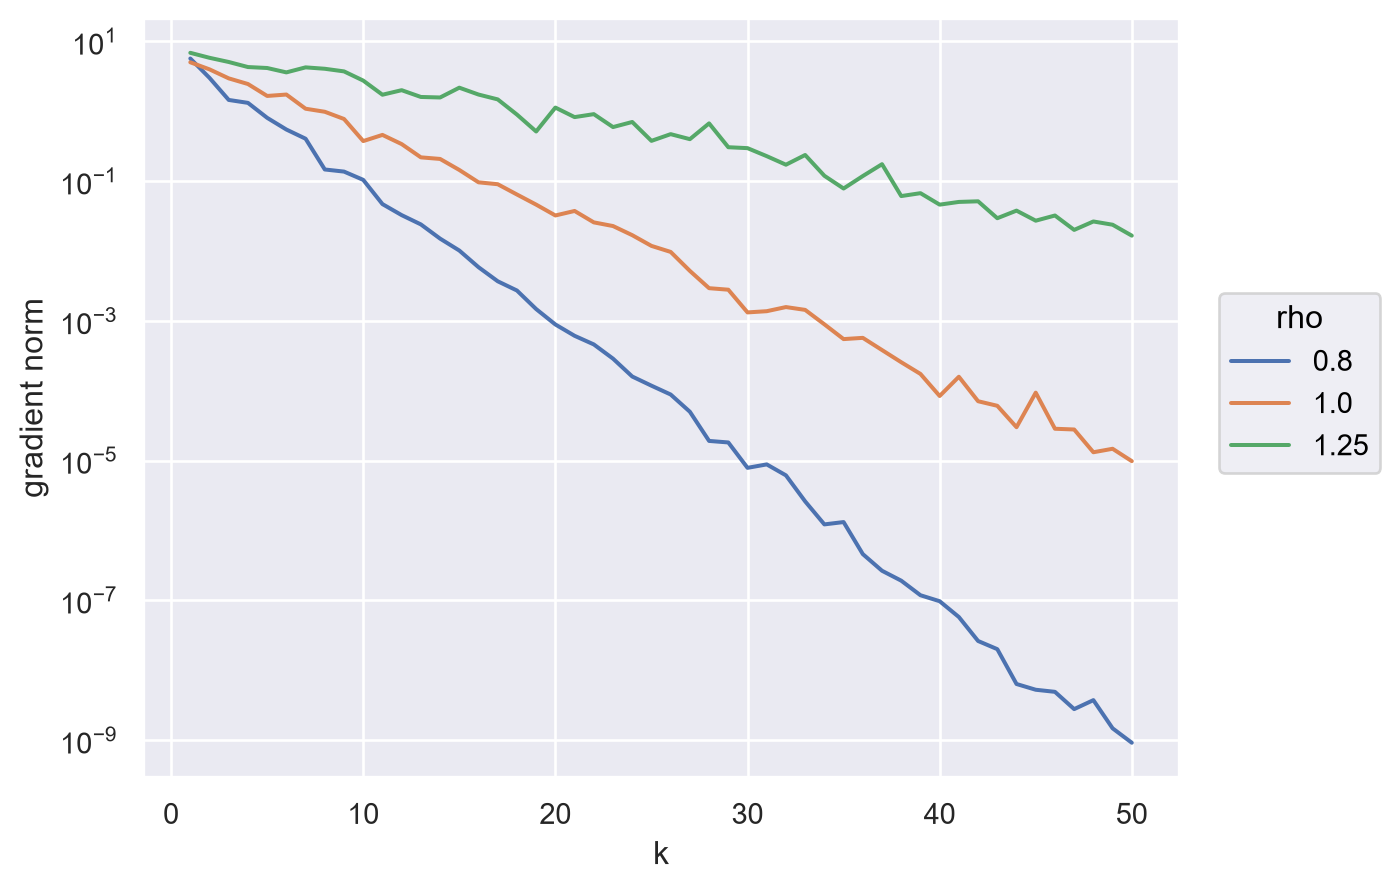

In [39]:
torch.manual_seed(0)
Q, _ = torch.linalg.qr(torch.randn(64, 64))
x_seq = torch.randn(60, 64)
gradient_norms = []
for rho in [0.8, 1.0, 1.25]:
  W_rnn = rho * Q
  for k in range(1, 51):
    h = torch.zeros(64)
    for t in range(60):
      h = torch.tanh(W_rnn @ h + x_seq[t] * 0.5)
      if t == 59 - k:
        h_start = h.detach().requires_grad_()
        h = h_start
    direction = torch.randn(64)
    (gradient,) = torch.autograd.grad(h @ direction, h_start)
    gradient_norms.append({'rho': rho, 'k': k, 'gradient norm': gradient.norm().item()})
so.Plot(pl.DataFrame(gradient_norms), x='k', y='gradient norm', color='rho').add(so.Line()).scale(y='log', color=so.Nominal())

In [40]:
vocab_rnn = {w: k + 1 for k, (w, _) in enumerate(frequency.most_common(10_000))}     # 0 = padding or unknown word
sequences_text = torch.zeros(len(documents), 100, dtype=torch.long)
for d, t in enumerate(tokens):
  ids = [vocab_rnn.get(w, 0) for w in t][:100]
  sequences_text[d, :len(ids)] = torch.tensor(ids, dtype=torch.long)
lengths = torch.tensor([max(1, min(len(t), 100)) for t in tokens])
class LSTMClassifier(torch.nn.Module):
  def __init__(self):
    super().__init__()
    self.embedding = torch.nn.Embedding(10_001, 64, padding_idx=0)
    self.lstm = torch.nn.LSTM(64, 64, batch_first=True)
    self.out = torch.nn.Linear(64, len(CATEGORIES))
  def forward(self, x, lengths):
    packed = torch.nn.utils.rnn.pack_padded_sequence(self.embedding(x), lengths, batch_first=True, enforce_sorted=False)
    return self.out(self.lstm(packed)[1][0][-1])
torch.manual_seed(0)
lstm = LSTMClassifier()
optimizer = torch.optim.Adam(lstm.parameters(), lr=3e-3)
y_text = torch.tensor(newsgroup)
train_t, test_t = torch.tensor(train_docs), torch.tensor(test_docs)
for epoch in range(4):
  for b in train_t[torch.randperm(len(train_t))].split(64):
    loss = torch.nn.functional.cross_entropy(lstm(sequences_text[b], lengths[b]), y_text[b])
    optimizer.zero_grad(); loss.backward()
    torch.nn.utils.clip_grad_norm_(lstm.parameters(), 1.0)                         # against exploding gradients
    optimizer.step()
with torch.no_grad():
  lstm_accuracy = (lstm(sequences_text[test_t], lengths[test_t]).argmax(dim=1) == y_text[test_t]).float().mean().item()
{'LSTM test accuracy': lstm_accuracy}

{'LSTM test accuracy': 0.5521367788314819}

**Conclusion** For the simple recurrent unit, the gradient of $h_{60}$ with respect to $h_{60-k}$ decreases geometrically with $k$: by $9$ orders of magnitude after $50$ steps for $\rho = 0.8$, $5$ for $\rho = 1$, and still $3$ for $\rho = 1.25$: the saturation of the $\tanh$ (whose derivative is less than $1$) prevents the explosion here but makes the gradients vanish, so that the network cannot learn long dependencies. The LSTM classifier reaches only $0.55$ of test accuracy after $4$ epochs, far below the bag of words with a logistic regression ($0.83$): with $4000$ training documents and short training, a recurrent network learns slowly, and the topic of a document is well described by its words without their order.

---

### Attention and a small transformer (★★★)

Self-attention mixes the vectors of a sequence $X \in \mathbb{R}^{T \times d}$ with weights computed from the data: $\text{softmax}\big(QK^\top/\sqrt{d_k}\big)V$ with $Q = XW_Q$, $K = XW_K$, $V = XW_V$. It is *permutation equivariant*: without positional encodings, a transformer sees a bag of words (PC5). All the positions are processed in parallel, unlike a recurrent network.

**Question** Implement a single-head self-attention by hand and check that permuting its input permutes its output. Then train a small transformer classifier (`torch.nn.TransformerEncoder`, $1$ layer, dimension $64$, $4$ heads, learned positional embeddings, mean pooling over the non-padded positions, $4$ epochs) on the same sequences ($100$ first words), and compare its test accuracy with the LSTM and the bag of words.

**Answer**

In [41]:
torch.manual_seed(0)
d_model = 16
W_Q, W_K, W_V = (torch.randn(d_model, d_model) / d_model ** 0.5 for _ in range(3))
def self_attention(X):
  Q_, K_, V_ = X @ W_Q, X @ W_K, X @ W_V
  return torch.softmax(Q_ @ K_.T / d_model ** 0.5, dim=1) @ V_
X_seq = torch.randn(10, d_model)
permutation = torch.randperm(10)
print('permutation equivariance error:', (self_attention(X_seq[permutation]) - self_attention(X_seq)[permutation]).abs().max().item())

permutation equivariance error: 3.5762786865234375e-07


In [42]:
vocab_rnn = {w: k + 1 for k, (w, _) in enumerate(frequency.most_common(10_000))}
sequences_text = torch.zeros(len(documents), 100, dtype=torch.long)
for d, t in enumerate(tokens):
  ids = [vocab_rnn.get(w, 0) for w in t][:100]
  sequences_text[d, :len(ids)] = torch.tensor(ids, dtype=torch.long)
class TransformerClassifier(torch.nn.Module):
  def __init__(self, d=64):
    super().__init__()
    self.embedding = torch.nn.Embedding(10_001, d, padding_idx=0)
    self.position = torch.nn.Embedding(100, d)
    layer = torch.nn.TransformerEncoderLayer(d, nhead=4, dim_feedforward=128, dropout=0.1, batch_first=True)
    self.encoder = torch.nn.TransformerEncoder(layer, num_layers=1, enable_nested_tensor=False)
    self.out = torch.nn.Linear(d, len(CATEGORIES))
  def forward(self, x):
    padding = x == 0
    h = self.encoder(self.embedding(x) + self.position(torch.arange(x.shape[1])), src_key_padding_mask=padding)
    mask = (~padding).float()[:, :, None]
    return self.out((h * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1))
torch.manual_seed(0)
transformer = TransformerClassifier()
optimizer = torch.optim.Adam(transformer.parameters(), lr=1e-3)
y_text = torch.tensor(newsgroup)
train_t, test_t = torch.tensor(train_docs), torch.tensor(test_docs)
sequences_text[sequences_text.sum(dim=1) == 0, 0] = 1                                # avoid fully padded (empty) documents
for epoch in range(4):
  transformer.train()
  for b in train_t[torch.randperm(len(train_t))].split(64):
    loss = torch.nn.functional.cross_entropy(transformer(sequences_text[b]), y_text[b])
    optimizer.zero_grad(); loss.backward(); optimizer.step()
transformer.eval()
with torch.no_grad():
  transformer_accuracy = (transformer(sequences_text[test_t]).argmax(dim=1) == y_text[test_t]).float().mean().item()
{'transformer test accuracy': transformer_accuracy}

{'transformer test accuracy': 0.6074073910713196}

**Conclusion** The self-attention is permutation equivariant up to the floating point precision (an error of order $10^{-7}$): without positional embeddings, it sees a bag of words. The small transformer reaches $0.61$ of test accuracy, better than the LSTM ($0.55$) for the same budget (all the positions are processed in parallel and each word attends directly to all the others), but still far below the tf-idf logistic regression ($0.83$). Transformers need much more data, or pre-training: the strength of language models comes from pre-training on huge corpora, then fine-tuning or using their embeddings.

---

## About this lab

**Use of AI.** Artificial intelligence tools have been used to revise the content of this lab. The main contributor takes full responsibility for this content.

**License.** The texts of this lab are under the [Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) license (CC BY-SA 4.0), and its code under the [MIT](https://opensource.org/license/mit) license; the datasets keep their own licenses. Main contributor: E. Le Pennec. Contributors: S. Boucheron, A. Dieuleveut, A.K. Fermin, S. Gadat, S. Gaiffas, B. Goujaud, A. Guilloux, Ch. Keribin, Th. Klein, E. Matzner, J. Read, M. Sangnier, E. Scornet.